# StoryWeaver on Kaggle — All-in-one Notebook

**StoryWeaver: A Unified World Model for Knowledge-Enhanced Story Character Customization** (AAAI 2025)

Notebook này gộp toàn bộ `TBC_dataset.py` + `train.py` + `sample.py` + `train.sh` + `sample.sh` thành một file chạy được trực tiếp trên Kaggle.

## Cấu trúc notebook

| Phần | Nội dung |
|---|---|
| 0 | Kiểm tra môi trường (GPU / RAM / disk) |
| 1 | Cài đặt thư viện |
| 2 | **CONFIG** — chỗ duy nhất bạn cần sửa |
| 3 | Patch cross-attention (Knowledge-Enhanced Spatial Guidance) |
| 4 | `Autok_encoder` + hàm `validation` (sampling loop) |
| 5 | 3 lớp Dataset của TBC-Bench |
| 6 | **Smoke test** — kiểm tra dữ liệu & 1 bước train giả trước khi chạy thật |
| 7 | Train |
| 8 | Sample truyện mới |
| 9 | Xem kết quả & đóng gói output |

## Trước khi chạy — 3 việc bắt buộc

1. **Settings → Accelerator → GPU** (T4 x2 hoặc P100).
2. **Settings → Internet → On** (để tải Stable Diffusion 1.5 từ HuggingFace).
3. **Add Input → Dataset** → chọn dataset `TBC_Bench` bạn đã upload.

> Đọc file `HUONG_DAN.md` đi kèm để biết chi tiết từng bước.

In [ ]:
import sys

# Check if 'google.colab' is registered in the system modules
if 'google.colab' in sys.modules:
    print("Running on Google Colab. Mount drive to dataset")
    from google.colab import drive
    drive.mount('/content/drive')
    !mkdir -p /root/TBC_Bench
    !rsync -ah --progress /content/drive/MyDrive/DLDT/TBC_Bench /root/
    DATASET = "/root/TBC_Bench"
else:
    print("Not running on Google Colab")
    DATASET = "/kaggle/input"

Running on Google Colab. Mount drive to dataset
Mounted at /content/drive
sending incremental file list
TBC_Bench/
TBC_Bench/eval-plot/
TBC_Bench/eval-plot/eval_new_story/
TBC_Bench/eval-plot/eval_new_story/Frozen/
TBC_Bench/eval-plot/eval_new_story/Frozen/Multi/
TBC_Bench/eval-plot/eval_new_story/Frozen/Multi/all/
TBC_Bench/eval-plot/eval_new_story/Frozen/Multi/all/1.txt
          1.02K 100%    0.00kB/s    0:00:00 (xfr#1, to-chk=658/669)
TBC_Bench/eval-plot/eval_new_story/Frozen/Multi/all/10.txt
          1.27K 100%    2.47kB/s    0:00:00 (xfr#2, to-chk=657/669)
TBC_Bench/eval-plot/eval_new_story/Frozen/Multi/all/2.txt
            838 100%    0.80kB/s    0:00:01 (xfr#3, to-chk=656/669)
TBC_Bench/eval-plot/eval_new_story/Frozen/Multi/all/3.txt
          1.18K 100%    0.83kB/s    0:00:01 (xfr#4, to-chk=655/669)
TBC_Bench/eval-plot/eval_new_story/Frozen/Multi/all/4.txt
            958 100%    0.00kB/s    0:00:00 (xfr#5, to-chk=654/669)
TBC_Bench/eval-plot/eval_new_story/Frozen/Multi/all/

---
## 0. Kiểm tra môi trường

Chạy cell này trước để biết bạn đang có GPU gì, còn bao nhiêu disk. Nếu `CUDA available = False` thì bạn chưa bật GPU trong Settings.

In [ ]:
# === 0. KIEM TRA MOI TRUONG ===
import os, sys, subprocess, shutil, platform

# Kaggle co the cap 2 GPU (T4 x2). Notebook nay chay 1 process -> chi dung GPU 0.
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
# Tat cac thu vien telemetry / tracker khong can thiet
os.environ.setdefault("WANDB_DISABLED", "true")
os.environ.setdefault("HF_HUB_DISABLE_TELEMETRY", "1")

print("Python :", sys.version.split()[0], "|", platform.platform())
print("-" * 70)
try:
    out = subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total,driver_version",
                          "--format=csv,noheader"], capture_output=True, text=True).stdout
except FileNotFoundError:
    out = ""
print(out.strip() or "!! Khong thay GPU -> bat Settings > Accelerator > GPU roi chay lai")
print("-" * 70)
for p in ["/kaggle/input", "/kaggle/working", "/tmp"]:
    if os.path.isdir(p):
        t, u, f = shutil.disk_usage(p)
        print(f"{p:18s} free = {f/2**30:6.1f} GB / total {t/2**30:6.1f} GB")

try:
    import torch
    print("-" * 70)
    print("torch :", torch.__version__, "| CUDA available =", torch.cuda.is_available())
    if torch.cuda.is_available():
        print("GPU   :", torch.cuda.get_device_name(0),
              f"({torch.cuda.get_device_properties(0).total_memory/2**30:.1f} GB)")
except ImportError:
    print("torch chua duoc cai (se cai o cell sau)")

print("-" * 70)
print("Cac dataset da mount:")
for d in sorted(os.listdir(DATASET)) if os.path.isdir(DATASET) else []:
    print(DATASET + "/" + d)

Python : 3.13.15 | Linux-6.6.122+-x86_64-with-glibc2.39
----------------------------------------------------------------------
Tesla T4, 15360 MiB, 580.82.07
----------------------------------------------------------------------
/kaggle/input      free =   66.4 GB / total  118.9 GB
/tmp               free =   64.9 GB / total  112.6 GB
----------------------------------------------------------------------
torch : 2.11.0+cu128 | CUDA available = True
GPU   : Tesla T4 (14.6 GB)
----------------------------------------------------------------------
Cac dataset da mount:
/root/TBC_Bench/eval-plot
/root/TBC_Bench/train-folder


---
## 1. Cài đặt thư viện

Kaggle đã có `torch`, `numpy`, `opencv`, `matplotlib`. Ta **không** cài lại torch (rất lâu và dễ vỡ CUDA), chỉ pin các thư viện phía HuggingFace cho khớp với code gốc:

* `diffusers==0.31.0` — bắt buộc, vì code patch trực tiếp vào `Transformer2DModel` / `AttnProcessor2_0` của bản này.
* `transformers==4.46.1`, `accelerate==1.0.1`, `huggingface_hub==0.26.2` — theo `requirements.txt`.
* `einops`, `bitsandbytes` (Adam 8-bit để tiết kiệm VRAM).

Sau khi cài xong, **nếu notebook báo cần restart thì cứ chạy tiếp**, các cell sau đều import lại từ đầu.

In [ ]:
!pip install -q "diffusers==0.31.0" "transformers==4.47.0" "tokenizers==0.21.0" "accelerate==1.0.1" "huggingface_hub==0.26.2" "einops==0.8.0" "bitsandbytes"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.5/43.5 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 53.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 102.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 93.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 330.9/330.9 kB 31.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 447.5/447.5 kB 37.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.2/43.2 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 14.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.26.2 which is incompatible.


In [ ]:
!pip install -q "importlib_metadata" "regex" "filelock" "packaging" "pyyaml" "requests" "tqdm"

In [ ]:
# === 1. CAI DAT THU VIEN ===
import subprocess
import sys

# ============================================================
# QUAN TRONG:
# KHONG importlib.reload(torch)
# KHONG reload bat ky module nao da dung torch
# ============================================================
import torch
import diffusers
import transformers
import accelerate
import huggingface_hub
import einops
import safetensors

print("=" * 70)
print("VERSION")
print("torch          :", torch.__version__)
print("diffusers      :", diffusers.__version__)
print("transformers   :", transformers.__version__)
print("accelerate     :", accelerate.__version__)
print("huggingface_hub:", huggingface_hub.__version__)
print("einops         :", einops.__version__)
print("safetensors    :", safetensors.__version__)

print("=" * 70)
print("CUDA available :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU            :", torch.cuda.get_device_name(0))
    print("CUDA version   :", torch.version.cuda)

print("=" * 70)
print("PyTorch da duoc giu nguyen, KHONG reload.")

The cache for model files in Transformers v4.22.0 has been updated. Migrating your old cache. This is a one-time only operation. You can interrupt this and resume the migration later on by calling `transformers.utils.move_cache()`.


0it [00:00, ?it/s]

VERSION
torch          : 2.11.0+cu128
diffusers      : 0.31.0
transformers   : 4.47.0
accelerate     : 1.0.1
huggingface_hub: 0.26.2
einops         : 0.8.0
safetensors    : 0.8.0
CUDA available : True
GPU            : Tesla T4
CUDA version   : 12.8
PyTorch da duoc giu nguyen, KHONG reload.


---
## 2. CONFIG — chỗ duy nhất bạn cần sửa

Cell này thay cho `train.sh` + `sample.sh`. Ý nghĩa từng tham số:

| Tham số | Tương ứng trong shell script | Ghi chú |
|---|---|---|
| `STORY_WORLD` | `DATA_DIR` / `DATA_NAME` | `Pororo_the_Little_Penguin` hoặc `Frozen`. `DATA_NAME` tự suy ra. |
| `PRETRAINED_MODEL` | `MODEL_NAME` | `runwayml/stable-diffusion-v1-5` đã bị xoá khỏi HF Hub → dùng repo mirror. |
| `MAX_CHAR` | `MAX_CHAR` | Số nhân vật tối đa trong 1 khung truyện. |
| `MAX_TRAIN_STEPS` | `max_train_steps` | Paper dùng 20000. Kaggle giới hạn 12h/session → xem `TIME_BUDGET_MIN`. |
| `SCALE` | `SCALE` khi sample | time-aware scale, paper dùng 2.5. |
| `SMOKE_TEST` | – | `True` = chạy siêu nhanh (2 step, 5 bước khử nhiễu) để kiểm tra pipeline. |

**Quy trình khuyến nghị:** để `SMOKE_TEST = True` chạy hết notebook một lượt (≈10 phút). Khi thấy ảnh output ra được (dù xấu) thì đổi `SMOKE_TEST = False` và chạy lại phần Train.

In [ ]:
# === 2. CONFIG ===
import os, glob, math, types

def _autodetect_tbc_bench():
    """Tim thu muc TBC_Bench trong /kaggle/input, bat ke ban dat ten dataset la gi."""
    for p in DATASET:
        for c in sorted(glob.glob(p)):
            if os.path.isdir(os.path.join(c, "train-folder")):
                return c
    return None


CFG = types.SimpleNamespace(

    # ---------------------------------------------------------------- DU LIEU
    # De None de tu dong tim. Hoac gan tay, vi du:
    # DATA_ROOT = "/kaggle/input/tbc-bench/TBC_Bench"
    DATA_ROOT       = DATASET,
    STORY_WORLD     = "Pororo_the_Little_Penguin",   # hoac "Frozen"

    # ---------------------------------------------------------------- MODEL
    # repo goc 'runwayml/stable-diffusion-v1-5' da bi xoa khoi HuggingFace Hub.
    # Cac lua chon con dung duoc (thu lan luot tu tren xuong):
    PRETRAINED_MODEL = "stable-diffusion-v1-5/stable-diffusion-v1-5",
    MODEL_FALLBACKS  = ["botp/stable-diffusion-v1-5",
                        "sd-legacy/stable-diffusion-v1-5",
                        "Lykon/DreamShaper"],
    # Neu muon train tiep tu ket qua session truoc: add output cu lam Input dataset
    # roi tro vao thu muc 'pipeline' (chua unet/ va k_encoder.pt). De None neu train tu dau.
    RESUME_PIPELINE_DIR = None,

    # ---------------------------------------------------------------- TRAIN
    OUTPUT_DIR      = "/kaggle/working/output",
    RESOLUTION      = 512,        # anh 512 x 896 (ti le 4:7). Phai la boi so cua 256:
                                  # 256 (nhe VRAM, 256x448) | 512 (nhu paper) | 768 | 1024
    MAX_CHAR        = 2,
    TRAIN_BATCH     = 1,
    GRAD_ACCUM      = 4,
    GRAD_CKPT       = True,       # gradient checkpointing: bat buoc tren T4/P100
    MAX_TRAIN_STEPS = 3000,       # paper: 20000 (khong the chay het trong 1 session Kaggle)
    CKPT_STEPS      = 500,        # moi bao nhieu step thi luu pipeline + sinh anh kiem tra
    LR              = 7e-6,
    LR_SCHEDULER    = "constant",
    LR_WARMUP       = 0,
    MAX_GRAD_NORM   = 1.0,
    SEED            = 42,
    MIXED_PRECISION = "fp16",     # "fp16" | "no". T4/P100 nen dung fp16
    USE_8BIT_ADAM   = True,       # can bitsandbytes; giam ~5GB VRAM
    TRAINABLE       = "all",      # "all" = unet + k_encoder (dung nhu paper)
                                  # "cross_attn" = chi cross-attn + k_encoder (it VRAM, nhanh)
    SCALE_TRAIN     = 1.0,        # scale cua k_encoder khi train
    TIME_BUDGET_MIN = 540,        # tu dong dung & luu sau N phut (Kaggle gioi han 12h = 720)
    SAVE_FULL_STATE = False,      # True = luu ca optimizer state (nang ~10GB/ckpt)
    CKPT_TOTAL_LIMIT = 1,
    SAVE_FULL_PIPELINE = False,   # False = chi luu unet/ + k_encoder.pt (~3.4GB, du de sample)
                                  # True  = luu ca pipeline SD hoan chinh (~4.9GB)
    VAL_INFER_STEPS = 50,         # so buoc khu nhieu khi sinh anh kiem tra trong luc train

    # ---------------------------------------------------------------- SAMPLE
    SAMPLE_DIR      = "/kaggle/working/sample",
    SCALE           = 2.5,        # time-aware scale khi sample (paper: 2.5)
    GUIDANCE_SCALE  = 5.0,        # classifier-free guidance
    NUM_INFER_STEPS = 100,        # so buoc khu nhieu khi sample
    SEED_NUM        = 1,          # so seed random cho moi truyen
    # Truyen moi de sample. None = tu chon file dau tien trong eval_new_story/<world>/Multi/all
    STORY_TXT       = None,
    MAX_VAL_BATCHES = 4,          # gioi han so anh sinh ra o moi lan validate khi train

    # ---------------------------------------------------------------- KHAC
    SMOKE_TEST          = False,   # True = chay nhanh de kiem tra pipeline
    FAST_SELF_ATTENTION = True,   # True = giu SDPA cho self-attn (tiet kiem RAM, ket qua tuong duong)
    APPLY_MASK_ALL_HEADS = False, # False = giong y code goc cua tac gia (chi head dau tien)
                                  # True  = ap spatial guidance cho tat ca attention head
    STORE_ATTN_MAP      = False,  # True = luu attention map de visualize (ton RAM)
    SOFT_MASK           = False,  # False = mask cung +-s nhu code goc (KHONG truyen gradient
                                  #         ve k_encoder; k_encoder chi hoc tu loss_reg).
                                  # True  = mask mem (sigmoid) -> loss_mse cung day duoc
                                  #         mean/cor cua k_encoder. Khac paper, de thu nghiem.
    SOFT_MASK_BETA      = 40.0,   # do "cung" cua mask mem (cang lon cang giong mask cung)
    DETECT_ANOMALY      = False,  # code goc bat torch.autograd.set_detect_anomaly -> rat cham
)

# ---------------------------------------------------------------------------
# Suy dien duong dan + kiem tra
# ---------------------------------------------------------------------------
if CFG.DATA_ROOT is None:
    CFG.DATA_ROOT = _autodetect_tbc_bench()

assert CFG.DATA_ROOT and os.path.isdir(CFG.DATA_ROOT), (
    "Khong tim thay TBC_Bench. Hay 'Add Input' dataset roi gan tay CFG.DATA_ROOT.\n"
    "Cac thu muc dang co: " + str(sorted(glob.glob('/kaggle/input/*')))
)

CFG.DATA_NAME     = "Frozen" if "Frozen" in CFG.STORY_WORLD else "Pororo"
# Anh co ti le 4:7 (512 x 896). Code goc viet int(res/9)*16, dung 4:7 dung o res=512
# nhung lech o cac res khac -> dung cong thuc 4:7 tuong minh.
CFG.WIDTH         = CFG.RESOLUTION // 4 * 7               # 512 -> 896
CFG.TRAIN_DIR     = os.path.join(CFG.DATA_ROOT, "train-folder", CFG.STORY_WORLD)
CFG.CHARACTER_DIR = os.path.join(CFG.TRAIN_DIR, "character")
CFG.STYLE_FILE    = os.path.join(CFG.TRAIN_DIR, "style.txt")
CFG.TEST_DIR      = os.path.join(CFG.DATA_ROOT, "eval-plot", "eval_train", "each", CFG.STORY_WORLD)
CFG.NEW_STORY_DIR = os.path.join(CFG.DATA_ROOT, "eval-plot", "eval_new_story", CFG.STORY_WORLD)
CFG.OUTPUT_DIR    = os.path.join(CFG.OUTPUT_DIR, CFG.DATA_NAME)
CFG.PIPELINE_DIR  = os.path.join(CFG.OUTPUT_DIR, "pipeline")

def _check_resolution(res, width, n_levels=4):
    """Processor cua StoryWeaver suy ra (H,W) tu so token: H*W = HW voi H:W = 4:7.
    Vi vay o MOI tang cua U-Net, HW/28 phai la so chinh phuong."""
    h, w, bad = res // 8, width // 8, []
    for lv in range(n_levels):
        hw = h * w
        m = int(round(math.sqrt(hw / 28)))
        if m * 4 != h or m * 7 != w:
            bad.append("tang %d: latent %dx%d" % (lv, h, w))
        h, w = -(-h // 2), -(-w // 2)
    return bad

_bad = _check_resolution(CFG.RESOLUTION, CFG.WIDTH)
if _bad:
    print("!! CANH BAO: RESOLUTION =", CFG.RESOLUTION, "khong tuong thich:", _bad)
    print("   Hay dung boi so cua 256 (256 / 512 / 768 / 1024). Paper dung 512.")

if CFG.STORY_TXT is None:
    cands = sorted(glob.glob(os.path.join(CFG.NEW_STORY_DIR, "Multi", "all", "*.txt")))
    CFG.STORY_TXT = cands[0] if cands else None

if CFG.SMOKE_TEST:                      # cau hinh sieu nhanh de test pipeline
    CFG.MAX_TRAIN_STEPS  = 10
    CFG.CKPT_STEPS       = 2
    CFG.NUM_INFER_STEPS  = 10
    CFG.VAL_INFER_STEPS  = 10
    CFG.MAX_VAL_BATCHES  = 5
    CFG.SEED_NUM         = 1
    CFG.TIME_BUDGET_MIN  = 30

os.makedirs(CFG.OUTPUT_DIR, exist_ok=True)
os.makedirs(CFG.SAMPLE_DIR, exist_ok=True)

print("DATA_ROOT      :", CFG.DATA_ROOT)
print("STORY_WORLD    :", CFG.STORY_WORLD, "->", CFG.DATA_NAME)
print("TRAIN_DIR      :", CFG.TRAIN_DIR, "(ton tai:", os.path.isdir(CFG.TRAIN_DIR), ")")
print("CHARACTER_DIR  :", CFG.CHARACTER_DIR, "(ton tai:", os.path.isdir(CFG.CHARACTER_DIR), ")")
print("STYLE_FILE     :", CFG.STYLE_FILE, "(ton tai:", os.path.isfile(CFG.STYLE_FILE), ")")
print("TEST_DIR       :", CFG.TEST_DIR, "(ton tai:", os.path.isdir(CFG.TEST_DIR), ")")
print("NEW_STORY_DIR  :", CFG.NEW_STORY_DIR, "(ton tai:", os.path.isdir(CFG.NEW_STORY_DIR), ")")
print("STORY_TXT      :", CFG.STORY_TXT)
print("Anh train      : %d x %d  (latent %d x %d)"
      % (CFG.RESOLUTION, CFG.WIDTH, CFG.RESOLUTION // 8, CFG.WIDTH // 8))
print("SMOKE_TEST     :", CFG.SMOKE_TEST, "| MAX_TRAIN_STEPS =", CFG.MAX_TRAIN_STEPS)

DATA_ROOT      : /root/TBC_Bench
STORY_WORLD    : Pororo_the_Little_Penguin -> Pororo
TRAIN_DIR      : /root/TBC_Bench/train-folder/Pororo_the_Little_Penguin (ton tai: True )
CHARACTER_DIR  : /root/TBC_Bench/train-folder/Pororo_the_Little_Penguin/character (ton tai: True )
STYLE_FILE     : /root/TBC_Bench/train-folder/Pororo_the_Little_Penguin/style.txt (ton tai: True )
TEST_DIR       : /root/TBC_Bench/eval-plot/eval_train/each/Pororo_the_Little_Penguin (ton tai: True )
NEW_STORY_DIR  : /root/TBC_Bench/eval-plot/eval_new_story/Pororo_the_Little_Penguin (ton tai: True )
STORY_TXT      : /root/TBC_Bench/eval-plot/eval_new_story/Pororo_the_Little_Penguin/Multi/all/1.txt
Anh train      : 512 x 896  (latent 64 x 112)
SMOKE_TEST     : False | MAX_TRAIN_STEPS = 3000


---
## 3. Patch cross-attention — Knowledge-Enhanced Spatial Guidance

Đây là phần lõi của StoryWeaver, gộp từ `train.py` (và bản trùng lặp trong `sample.py`).

Ba thứ được patch vào `diffusers`:

1. `Attention.get_attention_scores` → trả về **cả** `attention_probs` và `attention_scores` (raw logits, chưa softmax) để cộng mask không gian vào logits.
2. `Transformer2DModel.forward` → nhồi `height`/`width` của latent hiện tại vào `cross_attention_kwargs`, đồng thời cho phép `encoder_hidden_states` là một `dict` (`text_feat` / `character_indice` / `mask`) thay vì tensor.
3. `StoryWeaverAttnProcessor` → cộng mask Gaussian của từng nhân vật vào logits ở đúng dải token của (a) mô tả ngoại hình nhân vật và (b) nhãn lớp thô (Loopy → *beaver*, Pororo → *gentoo penguin*, …).

**Hai khác biệt có chủ ý so với code gốc** (đều bật/tắt được ở CONFIG):

* `FAST_SELF_ATTENTION=True`: code gốc ghi đè `AttnProcessor2_0.__call__` toàn cục nên **self-attention cũng** đi qua đường `bmm` thủ công → ở 512×896 tốn ~0.8 GB/layer và tràn VRAM T4. Ở đây chỉ `attn2` (cross-attn) dùng processor riêng, `attn1` giữ SDPA. Toán học tương đương.
* `APPLY_MASK_ALL_HEADS=False`: code gốc lặp `for bsz in range(batch_size)` rồi index vào chiều `batch*heads` — với `batch=1` thì mask chỉ tác động lên **head đầu tiên**. Mặc định giữ nguyên hành vi gốc để tái lập được kết quả paper; đặt `True` nếu bạn muốn thử áp cho toàn bộ head.

`DETECT_ANOMALY=False`: code gốc bọc `torch.autograd.set_detect_anomaly(True)` quanh mỗi lần attention → chậm hơn nhiều lần, chỉ nên bật khi debug NaN.

In [ ]:
# === 3. PATCH CROSS-ATTENTION (Knowledge-Enhanced Spatial Guidance) ===
import math, os, re, random, shutil, logging, itertools, time, json
from glob import glob
from dataclasses import dataclass
from typing import Any, Dict, Optional, Tuple, List, Union
from contextlib import nullcontext

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.utils.checkpoint
from PIL import Image
from einops import rearrange
from tqdm.auto import tqdm

import diffusers
from diffusers import (AutoencoderKL, DDPMScheduler, LMSDiscreteScheduler,
                       StableDiffusionPipeline, UNet2DConditionModel)
from diffusers.models import Transformer2DModel
from diffusers.models.attention_processor import Attention, AttnProcessor, AttnProcessor2_0
from diffusers.utils import BaseOutput, is_torch_version

import transformers
from transformers import CLIPTextModel, CLIPTokenizer

logger = logging.getLogger("storyweaver")

# Bien global dieu khien hanh vi cua attention processor -------------------
is_cond   = False     # True khi dang chay nhanh conditional (de luu attn map)
attn_maps = {}        # ten layer -> attention map


# ---------------------------------------------------------------------------
# 3.1 get_attention_scores: tra ve CA probs va raw scores
# ---------------------------------------------------------------------------
def get_attention_scores(self, query, key, attention_mask=None):
    dtype = query.dtype
    if self.upcast_attention:
        query = query.float()
        key = key.float()

    if attention_mask is None:
        baddbmm_input = torch.empty(query.shape[0], query.shape[1], key.shape[1],
                                    dtype=query.dtype, device=query.device)
        beta = 0
    else:
        baddbmm_input = attention_mask
        beta = 1

    attention_scores = torch.baddbmm(baddbmm_input, query, key.transpose(-1, -2),
                                     beta=beta, alpha=self.scale)
    del baddbmm_input

    if self.upcast_softmax:
        attention_scores = attention_scores.float()

    attention_probs = attention_scores.softmax(dim=-1).to(dtype)
    return attention_probs, attention_scores


# ---------------------------------------------------------------------------
# 3.2 Transformer2DModel.forward: truyen height/width xuong attention
# ---------------------------------------------------------------------------
@dataclass
class Transformer2DModelOutput(BaseOutput):
    sample: torch.FloatTensor


def Transformer2DModelForward(
    self,
    hidden_states: torch.Tensor,
    encoder_hidden_states=None,
    timestep: Optional[torch.LongTensor] = None,
    added_cond_kwargs: Dict[str, torch.Tensor] = None,
    class_labels: Optional[torch.LongTensor] = None,
    cross_attention_kwargs: Dict[str, Any] = None,
    attention_mask: Optional[torch.Tensor] = None,
    encoder_attention_mask: Optional[torch.Tensor] = None,
    return_dict: bool = True,
):
    if attention_mask is not None and attention_mask.ndim == 2:
        attention_mask = (1 - attention_mask.to(hidden_states.dtype)) * -10000.0
        attention_mask = attention_mask.unsqueeze(1)
    if encoder_attention_mask is not None and encoder_attention_mask.ndim == 2:
        encoder_attention_mask = (1 - encoder_attention_mask.to(hidden_states.dtype)) * -10000.0
        encoder_attention_mask = encoder_attention_mask.unsqueeze(1)

    # 1. Input
    if self.is_input_continuous:
        batch, _, height, width = hidden_states.shape
        residual = hidden_states
        hidden_states = self.norm(hidden_states)
        if not self.use_linear_projection:
            hidden_states = self.proj_in(hidden_states)
            inner_dim = hidden_states.shape[1]
            hidden_states = hidden_states.permute(0, 2, 3, 1).reshape(batch, height * width, inner_dim)
        else:
            inner_dim = hidden_states.shape[1]
            hidden_states = hidden_states.permute(0, 2, 3, 1).reshape(batch, height * width, inner_dim)
            hidden_states = self.proj_in(hidden_states)
    elif self.is_input_vectorized:
        hidden_states = self.latent_image_embedding(hidden_states)
    elif self.is_input_patches:
        height = hidden_states.shape[-2] // self.patch_size
        width = hidden_states.shape[-1] // self.patch_size
        hidden_states = self.pos_embed(hidden_states)
        if self.adaln_single is not None:
            batch_size = hidden_states.shape[0]
            timestep, embedded_timestep = self.adaln_single(
                timestep, added_cond_kwargs, batch_size=batch_size, hidden_dtype=hidden_states.dtype)

    # >>> StoryWeaver: gui kich thuoc latent xuong attention processor <<<
    # Chi can khi visualize attention map. attn_call tu suy ra H,W tu so token
    # (H*W = HW, ti le 4:7) nen mac dinh khong inject -> tranh warning
    # "cross_attention_kwargs are not expected by AttnProcessor2_0" tu self-attn.
    if CFG.STORE_ATTN_MAP:
        cross_attention_kwargs = dict(cross_attention_kwargs or {})
        cross_attention_kwargs["height"] = height
        cross_attention_kwargs["width"] = width

    # 2. Blocks
    for block in self.transformer_blocks:
        if self.training and self.gradient_checkpointing:
            def create_custom_forward(module, return_dict=None):
                def custom_forward(*inputs):
                    if return_dict is not None:
                        return module(*inputs, return_dict=return_dict)
                    return module(*inputs)
                return custom_forward
            ckpt_kwargs = {"use_reentrant": False} if is_torch_version(">=", "1.11.0") else {}
            hidden_states = torch.utils.checkpoint.checkpoint(
                create_custom_forward(block),
                hidden_states, attention_mask, encoder_hidden_states,
                encoder_attention_mask, timestep, cross_attention_kwargs,
                class_labels, **ckpt_kwargs)
        else:
            hidden_states = block(
                hidden_states,
                attention_mask=attention_mask,
                encoder_hidden_states=encoder_hidden_states,
                encoder_attention_mask=encoder_attention_mask,
                timestep=timestep,
                cross_attention_kwargs=cross_attention_kwargs,
                class_labels=class_labels)

    # 3. Output
    if self.is_input_continuous:
        if not self.use_linear_projection:
            hidden_states = hidden_states.reshape(batch, height, width, inner_dim).permute(0, 3, 1, 2).contiguous()
            hidden_states = self.proj_out(hidden_states)
        else:
            hidden_states = self.proj_out(hidden_states)
            hidden_states = hidden_states.reshape(batch, height, width, inner_dim).permute(0, 3, 1, 2).contiguous()
        output = hidden_states + residual
    elif self.is_input_vectorized:
        hidden_states = self.norm_out(hidden_states)
        logits = self.out(hidden_states).permute(0, 2, 1)
        output = F.log_softmax(logits.double(), dim=1).float()
    if self.is_input_patches:
        if self.config.norm_type != "ada_norm_single":
            conditioning = self.transformer_blocks[0].norm1.emb(
                timestep, class_labels, hidden_dtype=hidden_states.dtype)
            shift, scale = self.proj_out_1(F.silu(conditioning)).chunk(2, dim=1)
            hidden_states = self.norm_out(hidden_states) * (1 + scale[:, None]) + shift[:, None]
            hidden_states = self.proj_out_2(hidden_states)
        elif self.config.norm_type == "ada_norm_single":
            shift, scale = (self.scale_shift_table[None] + embedded_timestep[:, None]).chunk(2, dim=1)
            hidden_states = self.norm_out(hidden_states) * (1 + scale) + shift
            hidden_states = self.proj_out(hidden_states).squeeze(1)
        if self.adaln_single is None:
            height = width = int(hidden_states.shape[1] ** 0.5)
        hidden_states = hidden_states.reshape(
            shape=(-1, height, width, self.patch_size, self.patch_size, self.out_channels))
        hidden_states = torch.einsum("nhwpqc->nchpwq", hidden_states)
        output = hidden_states.reshape(
            shape=(-1, self.out_channels, height * self.patch_size, width * self.patch_size))

    if not return_dict:
        return (output,)
    return Transformer2DModelOutput(sample=output)


# ---------------------------------------------------------------------------
# 3.3 Attention processor cong mask khong gian vao logits
# ---------------------------------------------------------------------------
def attn_call(self, attn: Attention, hidden_states, encoder_hidden_states=None,
              attention_mask=None, temb=None, scale=1.0, height=None, width=None, **kwargs):
    assert attention_mask is None
    residual = hidden_states

    if attn.spatial_norm is not None:
        hidden_states = attn.spatial_norm(hidden_states, temb)

    input_ndim = hidden_states.ndim
    if input_ndim == 4:
        batch_size, channel, height, width = hidden_states.shape
        hidden_states = hidden_states.view(batch_size, channel, height * width).transpose(1, 2)

    batch_size, sequence_length, _ = (
        hidden_states.shape if encoder_hidden_states is None
        else encoder_hidden_states["text_feat"].shape)
    attention_mask = attn.prepare_attention_mask(attention_mask, sequence_length, batch_size)

    if attn.group_norm is not None:
        hidden_states = attn.group_norm(hidden_states.transpose(1, 2)).transpose(1, 2)

    query = attn.to_q(hidden_states)
    context = hidden_states if encoder_hidden_states is None else encoder_hidden_states["text_feat"]
    if encoder_hidden_states is not None and attn.norm_cross:
        context = attn.norm_encoder_hidden_states(context)
    key, value = attn.to_k(context), attn.to_v(context)

    query = attn.head_to_batch_dim(query)
    key = attn.head_to_batch_dim(key)
    value = attn.head_to_batch_dim(value)

    attention_probs, attention_scores = attn.get_attention_scores(query, key, attention_mask)

    anomaly_ctx = torch.autograd.set_detect_anomaly(True) if CFG.DETECT_ANOMALY else nullcontext()
    with anomaly_ctx:
        if encoder_hidden_states is not None:
            n_rows, HW, n_tok = attention_scores.shape
            heads = max(n_rows // batch_size, 1)
            mini = int(math.sqrt(HW / 4 / 7))
            H, W = mini * 4, mini * 7
            masks = encoder_hidden_states["mask"]
            indices = encoder_hidden_states["character_indice"]

            bias_full = None
            for bsz in range(batch_size):
                per_bias = None
                for idx in range(len(masks)):
                    m = masks[idx][[bsz], :, :].unsqueeze(0)                 # (1,1,Hf,Wf)
                    m = F.interpolate(m.float(), size=(H, W), mode="nearest")
                    m = m.to(attention_scores.device, attention_scores.dtype).reshape(HW, 1)
                    if float(m.min()) == 1.0 and float(m.max()) == 1.0:
                        continue                                             # nhanh uncond -> bo qua
                    if per_bias is None:
                        per_bias = torch.zeros(HW, n_tok, device=attention_scores.device,
                                               dtype=attention_scores.dtype)
                    desc_s = int(indices[idx][0][bsz])
                    desc_e = int(indices[idx][1][bsz]) if int(indices[idx][1][bsz]) <= n_tok else n_tok
                    cls_s = int(indices[idx][2][bsz])
                    cls_e = int(indices[idx][3][bsz]) if int(indices[idx][1][bsz]) <= n_tok else n_tok
                    if cls_e > cls_s:
                        per_bias[:, cls_s:cls_e] = per_bias[:, cls_s:cls_e] + m
                    if desc_e > desc_s:
                        per_bias[:, desc_s:desc_e] = per_bias[:, desc_s:desc_e] + m
                if per_bias is None:
                    continue
                if bias_full is None:
                    bias_full = torch.zeros_like(attention_scores)
                rows = (slice(bsz * heads, (bsz + 1) * heads) if CFG.APPLY_MASK_ALL_HEADS
                        else slice(bsz, bsz + 1))
                bias_full[rows] = per_bias

            if bias_full is not None:
                attention_probs = (attention_scores + bias_full).softmax(dim=-1)

            if CFG.STORE_ATTN_MAP and is_cond:
                self.attn_map = rearrange(attention_probs.detach(),
                                          "b (h w) d -> b d h w", h=(height or H))

    hidden_states = torch.bmm(attention_probs.to(value.dtype), value)
    hidden_states = attn.batch_to_head_dim(hidden_states)
    hidden_states = attn.to_out[0](hidden_states)
    hidden_states = attn.to_out[1](hidden_states)

    if input_ndim == 4:
        hidden_states = hidden_states.transpose(-1, -2).reshape(batch_size, channel, height, width)
    if attn.residual_connection:
        hidden_states = hidden_states + residual
    return hidden_states / attn.rescale_output_factor


class StoryWeaverAttnProcessor(AttnProcessor2_0):
    """Processor rieng cho attn2 (cross-attention)."""
    __call__ = attn_call


# ---------------------------------------------------------------------------
# 3.4 Cai patch vao model
# ---------------------------------------------------------------------------
def cross_attn_init():
    Attention.get_attention_scores = get_attention_scores
    if not CFG.FAST_SELF_ATTENTION:
        # Hanh vi y nhu code goc: moi attention (ke ca self-attn) dung attn_call
        AttnProcessor.__call__ = attn_call
        AttnProcessor2_0.__call__ = attn_call


def set_layer_with_name_and_path(model, target_name="attn2", current_path=""):
    for name, layer in model.named_children():
        if layer.__class__ == Transformer2DModel:
            layer.forward = Transformer2DModelForward.__get__(layer, Transformer2DModel)
        new_path = current_path + "." + name if current_path else name
        if name.endswith(target_name):
            layer.processor = StoryWeaverAttnProcessor()
        set_layer_with_name_and_path(layer, target_name, new_path)
    return model


def hook_fn(name, accumulate=True):
    def forward_hook(module, inp, out):
        if hasattr(module.processor, "attn_map"):
            global attn_maps
            if accumulate:
                attn_maps[name] = attn_maps.get(
                    name, torch.zeros_like(module.processor.attn_map)) + module.processor.attn_map
            else:
                attn_maps[name] = module.processor.attn_map
            del module.processor.attn_map
    return forward_hook


def register_cross_attention_hook(unet, accumulate=True):
    for name, module in unet.named_modules():
        if not name.split(".")[-1].startswith("attn2"):
            continue
        if isinstance(module.processor, (AttnProcessor, AttnProcessor2_0)):
            module.processor.store_attn_map = True
        module.register_forward_hook(hook_fn(name, accumulate))
    return unet


cross_attn_init()
print("Da patch diffusers", diffusers.__version__,
      "| FAST_SELF_ATTENTION =", CFG.FAST_SELF_ATTENTION,
      "| APPLY_MASK_ALL_HEADS =", CFG.APPLY_MASK_ALL_HEADS)

Da patch diffusers 0.31.0 | FAST_SELF_ATTENTION = True | APPLY_MASK_ALL_HEADS = False


---
## 4. `Autok_encoder` + vòng sampling

* **`Autok_encoder`** — từ đặc trưng pooled của CLIP text encoder cho mỗi nhân vật, dự đoán `mean` và `cor` của một Gaussian 2D trên mặt phẳng ảnh, cộng với **prior** (các nhân vật được giãn đều theo trục ngang). Gaussian đó được nhị phân hoá thành mask `±scale·(log t + 1)` — *time-aware*: nhiễu càng nhiều (t lớn) thì lực dẫn hướng không gian càng mạnh.
* **`validation()`** — vòng khử nhiễu LMS với classifier-free guidance, chạy 2 lần U-Net mỗi step (có mask / mask toàn 1).

Sửa so với code gốc: phần `MultivariateNormal` được ép về `float32` vì `torch.linalg.cholesky` không hỗ trợ `float16` → cần thiết để chạy được `mixed_precision="fp16"` trên T4/P100.

### Một lưu ý quan trọng về gradient

Trong code gốc, mask được tạo bằng cách **ghi đè toàn bộ phần tử** bằng hằng số:

```python
per_char_mask[[enhance_indice]]  =  time_aware_strength[i]
per_char_mask[[decrease_indice]] = -time_aware_strength[i]
```

Vì hai điều kiện phủ kín mọi phần tử, mask không còn phụ thuộc vào `probabilities` nữa → **`loss_mse` không truyền gradient nào về `Autok_encoder`**; nó chỉ được cập nhật bởi `loss_reg` (L1 kéo `mean`/`cor` về 0). Notebook này giữ đúng hành vi đó (mặc định `SOFT_MASK=False`) để tái lập được kết quả đã công bố, đồng thời có sẵn `SOFT_MASK=True` dùng mask mềm bằng sigmoid nếu bạn muốn thử để `loss_mse` thực sự học vị trí nhân vật — đây là một hướng ablation đáng thử cho seminar.

In [ ]:
# === 4. Autok_encoder + VONG SAMPLING ===

class Autok_encoder(nn.Module):
    """Du doan phan bo Gaussian 2D cho tung nhan vat -> mask khong gian time-aware."""

    def __init__(self, in_dim, out_dim, Height=512, Width=896, scale=1.0):
        super().__init__()
        self.in_dim, self.out_dim = in_dim, out_dim
        self.H, self.W = Height, Width
        self.scale = scale

        x = torch.linspace(-1, 1, Height)
        y = torch.linspace(-1, 1, Width)
        grid_x, grid_y = torch.meshgrid(x, y, indexing="ij")
        self.register_buffer("grid", torch.stack((grid_x, grid_y), dim=2), persistent=False)

        self.mean_predictor = nn.Sequential(
            nn.Linear(in_dim, 64), nn.LeakyReLU(), nn.LayerNorm(64),
            nn.Linear(64, out_dim), nn.Tanh())
        self.cor_predictor = nn.Sequential(
            nn.Linear(in_dim, 64), nn.LeakyReLU(), nn.LayerNorm(64),
            nn.Linear(64, out_dim), nn.Tanh())

    def set_scale(self, scale=1.0):
        self.scale = scale

    def forward(self, char_input_ids, char_indice_list, prior_means, prior_cors,
                text_encoder, timesteps):
        mask, all_mean, all_cor, all_sum_mean = [], [], [], []
        dev = text_encoder.device
        prior_means = prior_means.to(dev).float()
        prior_cors = prior_cors.to(dev).float()
        time_aware_strength = self.scale * (torch.log(timesteps.to(dev).float() + 1) + 1)

        for idx, (each_ids, each_indice) in enumerate(zip(char_input_ids, char_indice_list)):
            bs = char_input_ids[0].shape[0]
            each_feat = text_encoder(each_ids.to(dev), return_dict=False)[1]
            per_mean = self.mean_predictor(each_feat)
            per_cor = self.cor_predictor(each_feat)
            all_mean.append(per_mean)
            all_cor.append(per_cor)

            # float32: torch.linalg.cholesky khong ho tro float16
            per_cor_f = (per_cor.float() + 1.0).unsqueeze(2) * torch.eye(2, device=dev)
            mean = per_mean.float() + prior_means[:, idx, :]
            cor = per_cor_f * prior_cors[:, idx, :, :]
            all_sum_mean.append(mean)

            gaussian = torch.distributions.MultivariateNormal(mean, cor)
            grids = self.grid.to(dev).unsqueeze(-2).repeat(1, 1, bs, 1)
            probabilities = gaussian.log_prob(grids).exp()          # (H, W, bs)

            new_probabilities = []
            for i in range(probabilities.shape[-1]):
                per_char_mask = probabilities[:, :, i]
                pmax = per_char_mask.max().clamp_min(1e-12)
                r = per_char_mask / pmax                       # chuan hoa ve [0,1]
                s = time_aware_strength[i]
                if getattr(CFG, "SOFT_MASK", False):
                    # mask mem, kha vi -> loss_mse day duoc mean/cor cua k_encoder
                    per_char_mask = s * (2.0 * torch.sigmoid(
                        CFG.SOFT_MASK_BETA * (r - 0.85)) - 1.0)
                else:
                    # nhu code goc: ghi de TOAN BO phan tu bang +-s
                    # => mask khong con phu thuoc probabilities => khong co gradient.
                    per_char_mask = torch.where(r >= 0.85, s, -s)
                new_probabilities.append(per_char_mask)
            mask.append(torch.stack(new_probabilities))              # (bs, H, W)
        return mask, all_mean, all_cor, all_sum_mean


def load_k_encoder(path, scale=None, device="cpu"):
    """Nap Autok_encoder. Ho tro ca 2 dinh dang:
       - dict {state_dict, in_dim, out_dim, Height, Width, scale}  (notebook nay luu)
       - torch.save(module) nguyen ca object                        (code goc cua tac gia)
    """
    obj = torch.load(path, map_location="cpu", weights_only=False)
    if isinstance(obj, dict) and "state_dict" in obj:
        ke = Autok_encoder(obj["in_dim"], obj["out_dim"],
                           Height=obj["Height"], Width=obj["Width"],
                           scale=obj.get("scale", 1.0))
        ke.load_state_dict(obj["state_dict"])
    elif isinstance(obj, nn.Module):
        ke = obj
    else:
        raise ValueError("Khong hieu dinh dang k_encoder.pt: %s" % type(obj))
    if scale is not None:
        ke.set_scale(scale)
    return ke.to(device)


# ---------------------------------------------------------------------------
def th2image(image):
    image = (image / 2 + 0.5).clamp(0, 1)
    image = image.detach().cpu().permute(1, 2, 0).float().numpy()
    return Image.fromarray((image * 255).round().astype("uint8"))


def set_tensor_values_to_zero(tensor0, tensor1):
    mask = torch.all(torch.eq(tensor0, tensor1), dim=-1)
    tensor0 = tensor0.clone()
    tensor0[mask] = 0.0
    return tensor0


def calculate_cos_sim(mask_list):
    if len(mask_list) < 2:
        return torch.zeros((), device=mask_list[0].device)
    sims = [torch.cosine_similarity(mask_list[0], mask_list[i], dim=-1)
            for i in range(1, len(mask_list))]
    return torch.stack(sims).mean(dim=0).mean()


@torch.no_grad()
def validation(example, tokenizer, text_encoder, unet, vae, k_encoder, device,
               guidance_scale=5.0, seed=None, num_steps=100,
               height=None, width=None, autocast_dtype=None, progress=True):
    """Vong khu nhieu LMS + classifier-free guidance (gop tu train.py/sample.py)."""
    global is_cond
    height = height or CFG.RESOLUTION
    width = width or CFG.WIDTH
    lat_h, lat_w = height // 8, width // 8

    scheduler = LMSDiscreteScheduler(beta_start=0.00085, beta_end=0.012,
                                     beta_schedule="scaled_linear", num_train_timesteps=1000)
    bsz = len(example["text"])

    uncond_input = tokenizer([""], padding="max_length", truncation=True,
                             max_length=tokenizer.model_max_length,
                             return_tensors="pt").input_ids[0]
    uncond_input = uncond_input.unsqueeze(0).repeat(bsz, 1)
    uncond_embeddings = text_encoder(uncond_input.to(device), return_dict=False)[0]

    gen = torch.manual_seed(seed) if seed is not None else None
    latents = torch.randn((bsz, unet.config.in_channels, lat_h, lat_w), generator=gen)
    latents = latents.to(uncond_embeddings)
    scheduler.set_timesteps(num_steps)
    latents = latents * scheduler.init_noise_sigma

    uncond_mask = torch.ones((bsz, height, width))
    uncond_hidden = {"text_feat": uncond_embeddings,
                     "character_indice": example["character_desc_index"],
                     "mask": [uncond_mask] * len(example["character_list"])}

    text_feat = text_encoder(example["input_ids"].to(device), return_dict=False)[0]
    ac = (torch.autocast(device_type="cuda", dtype=autocast_dtype)
          if (autocast_dtype is not None and torch.cuda.is_available()) else nullcontext())

    cond_mask = None
    for t in tqdm(scheduler.timesteps, disable=not progress, leave=False, desc="denoise"):
        ts = t.unsqueeze(0).long().repeat(bsz)
        is_cond = True
        cond_mask, *_ = k_encoder(example["character_list"], example["character_desc_index"],
                                  example["mean"], example["cor"], text_encoder, ts)
        latent_model_input = scheduler.scale_model_input(latents, t)
        with ac:
            noise_pred_text = unet(latent_model_input, t, encoder_hidden_states={
                "text_feat": text_feat,
                "character_indice": example["character_desc_index"],
                "mask": cond_mask}).sample.float()
            is_cond = False
            noise_pred_uncond = unet(latent_model_input, t,
                                     encoder_hidden_states=uncond_hidden).sample.float()
        noise_pred = noise_pred_uncond + guidance_scale * (noise_pred_text - noise_pred_uncond)
        latents = scheduler.step(noise_pred, t, latents.float()).prev_sample

    with ac:
        images = vae.decode((1 / 0.18215 * latents).to(next(vae.parameters()).dtype)).sample
    return [th2image(im) for im in images], cond_mask


def save_strip(pil_images, path):
    """Ghep cac frame theo chieu ngang thanh 1 anh."""
    arr = np.concatenate([np.array(im) for im in pil_images], axis=1)
    Image.fromarray(arr).save(path)
    return path


print("Autok_encoder + validation() da san sang")

Autok_encoder + validation() da san sang


---
## 5. Dataset của TBC-Bench

Ba lớp, chuyển thẳng từ `TBC_dataset.py`:

| Lớp | Dùng ở đâu | Đầu vào |
|---|---|---|
| `BenchMark_Each_ClassConstrains` | train + validate | `train-folder/<world>/{image,caption,character,style.txt}` |
| `Benchmark_Eval_ClassConstrains` | test khi train | `eval-plot/eval_train/each/<world>/*.txt` |
| `TBC_Bench_Single_Story` | sample truyện mới | 1 file `.txt`, mỗi dòng là 1 khung truyện |

Cách hoạt động: caption chứa placeholder `<style>` và `<Pororo>`, `<Loopy>`… Chúng được thay bằng nội dung `style.txt` / `character/<Ten>.txt`, rồi code **dò lại vị trí token** của (a) đoạn mô tả nhân vật và (b) nhãn lớp thô (`Loopy → beaver`) trong chuỗi token CLIP — đây chính là dải token sẽ được cộng mask không gian.

Các chỗ đã làm chắc chắn hơn so với code gốc (dữ liệu lỗi 1 file sẽ không làm sập cả run 3000 step):

* đường dẫn caption suy ra bằng `os.path.splitext` thay vì `.replace('png','txt')` (dễ phá path);
* nếu không tìm thấy nhãn lớp thô trong caption → dùng luôn dải token mô tả, và **đếm + báo cáo** số file bị vậy;
* placeholder lạ (không phải tên nhân vật) được giữ nguyên thay vì `KeyError`;
* ảnh lỗi → ghi vào `error.txt` kèm tên file, không crash.

In [ ]:
# === 5. DATASET TBC-BENCH ===
from torch.utils.data import Dataset
from torchvision import transforms

CHAR_CLASS = {
    "Pororo": {
        "Crong": "dinosaur", "Eddy": "fox", "Harry": "bird", "Loopy": "beaver",
        "Petty": "Adélie penguin", "Poby": "polar bear", "Pororo": "gentoo penguin",
        "Rody": "robot", "Tongtong": "dragon",
    },
    "Frozen": {
        "Anna": "brown-hair girl", "Elsa": "white-hair girl", "Kristoff": "man",
        "Olaf": "snowman", "Sven": "reindeer",
    },
}
# Luu y: "Adélie penguin" giu nguyen dau nhu code goc cua tac gia.
# Neu caption trong dataset cua ban viet khong dau thi doi thanh "Adelie penguin".

IMG_EXTS = ("png", "jpg", "jpeg", "PNG", "JPG")
_WARNED = {"no_class": set(), "unknown_tag": set(), "too_many_char": set()}


def _read_first_line(path):
    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if line:
                return line
    return ""


def _caption_path_for(image_file):
    """image/<Char>/0001.png -> caption/<Char>/0001.txt (an toan hon .replace)."""
    stem = os.path.splitext(image_file)[0] + ".txt"
    parts = stem.split(os.sep)
    for i in range(len(parts) - 1, -1, -1):
        if parts[i] == "image":
            parts[i] = "caption"
            break
    return os.sep.join(parts)


class _TokenIndexMixin:
    """Dung chung logic do vi tri token mo ta nhan vat + nhan lop tho."""

    def _tokenize(self, text):
        return self.tokenizer(text, padding="max_length", truncation=True,
                              max_length=self.tokenizer.model_max_length,
                              return_tensors="pt").input_ids[0]

    def _eos_length(self, ids):
        for cnt, each in enumerate(ids):
            if self.tokenizer.decoder[each.item()] == self.tokenizer.eos_token:
                return cnt - 1
        return len(ids) - 1

    def _locate(self, input_ids, src_name=""):
        character_desc_index, character_list = [], []
        n_tok = len(input_ids)
        for each_char in self.character_desc_ids.keys():
            desc_ids = self.character_desc_ids[each_char]
            win = len(desc_ids[1:8])
            hits = torch.where(torch.all(
                input_ids.unfold(0, win, 1) == desc_ids[1:8], dim=1))[0]
            if len(hits) == 0:
                continue
            character_list.append(desc_ids)
            desc_start = int(hits[0])
            desc_end = desc_start + self._eos_length(desc_ids)

            cls_ids = self.char_class_ids[each_char]
            cwin = len(cls_ids[1:2])
            chits = torch.where(torch.all(
                input_ids.unfold(0, cwin, 1) == cls_ids[1:2], dim=1))[0]
            if len(chits) == 0:
                # Caption khong chua nhan lop tho -> dung lai dai token mo ta.
                if src_name and src_name not in _WARNED["no_class"]:
                    _WARNED["no_class"].add(src_name)
                cls_start, cls_end = desc_start, desc_end
            else:
                cls_start = int(chits[0])
                cls_end = cls_start + self._eos_length(cls_ids)
            character_desc_index.append([desc_start, desc_end, cls_start, cls_end])

        if not character_desc_index:
            raise ValueError(
                "Khong tim thay nhan vat nao trong caption: %s\n"
                "Kiem tra lai file character/*.txt co khop voi placeholder trong caption."
                % src_name)

        order = sorted(range(len(character_desc_index)),
                       key=lambda i: character_desc_index[i][0])
        character_desc_index = [character_desc_index[i] for i in order]
        character_list = [character_list[i] for i in order]

        self.actual_char = len(character_desc_index)
        self.multi_char = self.actual_char
        if self.actual_char > self.max_char:
            # Code goc khong cat bot -> prior_means[:, idx, :] se IndexError.
            # O day cat bot va ghi nhan lai de bao cao (nen tang CFG.MAX_CHAR).
            _WARNED["too_many_char"].add("%s (%d nhan vat > max_char=%d)"
                                         % (src_name, self.actual_char, self.max_char))
            self.actual_char = self.max_char
            self.multi_char = self.max_char
        while len(character_desc_index) < self.max_char:
            character_desc_index.append(character_desc_index[-1])
            character_list.append(character_list[-1])
        return (character_desc_index[:self.max_char], character_list[:self.max_char])

    def obtain_prior_dist(self, total_char):
        var = torch.eye(2).unsqueeze(0).repeat(self.max_char, 1, 1)
        if total_char > 1:
            per_mean = torch.linspace(-1 + (1 / self.max_char), 1 - (1 / self.max_char), total_char)
        else:
            per_mean = torch.zeros(1)
        mean = [[0.0, float(i)] for i in per_mean]
        mean += [[0.0, 0.0]] * (self.max_char - len(mean))
        return var, torch.tensor(mean[:self.max_char])

    def _build_char_tables(self, character_files):
        self.character_desc, self.character_desc_ids, self.char_class_ids = {}, {}, {}
        for each_txt in sorted(character_files):
            name = os.path.splitext(os.path.basename(each_txt))[0]
            if name not in self.char_class:
                continue
            text = _read_first_line(each_txt)
            self.character_desc[name] = text
            self.character_desc_ids[name] = self._tokenize(text)
            self.char_class_ids[name] = self._tokenize(self.char_class[name])

    def _replace_tags(self, text, style_text=None):
        if style_text is not None:
            text = text.replace("<style>", style_text)
        for tag in re.findall(r"<(.*?)>", text):
            if tag in self.character_desc:
                text = text.replace("<%s>" % tag, self.character_desc[tag])
            elif tag not in _WARNED["unknown_tag"]:
                _WARNED["unknown_tag"].add(tag)
        return text


# ---------------------------------------------------------------------------
class BenchMark_Each_ClassConstrains(Dataset, _TokenIndexMixin):
    """Dataset train: doc anh + caption tuong ung trong train-folder/<world>."""

    def __init__(self, data_root, tokenizer, resolution=512, center_crop=False,
                 random_flip=True, max_char=3, type="Pororo", width=None):
        self.data_root, self.tokenizer = data_root, tokenizer
        self.resolution = resolution
        self.width = width or int(resolution / 9) * 16
        self.char_class = CHAR_CLASS[type]
        self.max_char = max_char

        self.image_dir = sorted(sum(
            [glob(os.path.join(data_root, "image", "*", "*." + e)) for e in IMG_EXTS], []))
        self.character_dir = sorted(glob(os.path.join(data_root, "character", "*.txt")))
        self.style_file = os.path.join(data_root, "style.txt")
        self._build_char_tables(self.character_dir)
        self.style_text = _read_first_line(self.style_file) if os.path.isfile(self.style_file) else ""
        self.num_images = len(self.image_dir)
        self.error_text = os.path.join(CFG.OUTPUT_DIR, "error.txt")
        print("[train] %d anh | %d nhan vat | %s"
              % (self.num_images, len(self.character_desc), data_root))

        self.transforms = transforms.Compose([
            transforms.Resize(resolution, interpolation=transforms.InterpolationMode.BILINEAR),
            transforms.CenterCrop((resolution, self.width)) if center_crop
            else transforms.RandomCrop((resolution, self.width)),
            transforms.RandomHorizontalFlip() if random_flip else transforms.Lambda(lambda x: x),
            transforms.ToTensor(),
            transforms.Normalize([0.5], [0.5]),
        ])

    def __len__(self):
        return self.num_images

    def obtain_text(self, text_file):
        text = self._replace_tags(_read_first_line(text_file), self.style_text)
        input_ids = self._tokenize(text)
        idx, chars = self._locate(input_ids, text_file)
        return input_ids, text, chars, idx

    def __getitem__(self, i):
        image_file = self.image_dir[i]
        text_file = _caption_path_for(image_file)
        input_ids, text, character_list, character_desc_index = self.obtain_text(text_file)
        example = {"input_ids": input_ids, "text": text,
                   "character_desc_index": character_desc_index,
                   "character_list": character_list}
        try:
            example["pixel_values"] = self.transforms(Image.open(image_file).convert("RGB"))
        except Exception as e:
            with open(self.error_text, "a") as f:
                f.write("%s\t%s\n" % (image_file, e))
            example["pixel_values"] = torch.zeros((3, self.resolution, self.width))
        example["cor"], example["mean"] = self.obtain_prior_dist(self.actual_char)
        return example


# ---------------------------------------------------------------------------
class Benchmark_Eval_ClassConstrains(Dataset, _TokenIndexMixin):
    """Dataset test khi train: moi file .txt trong eval_train/each/<world> la 1 prompt."""

    def __init__(self, data_root, character_root, tokenizer, resolution=512,
                 max_char=2, type="Pororo", style_file=None):
        self.data_root, self.tokenizer = data_root, tokenizer
        self.resolution = resolution
        self.char_class = CHAR_CLASS[type]
        self.max_char = max_char
        self.caption_dir = sorted(glob(os.path.join(data_root, "*.txt")))
        self._build_char_tables(sorted(glob(os.path.join(character_root, "*.txt"))))
        self.style_text = (_read_first_line(style_file)
                           if style_file and os.path.isfile(style_file) else None)
        self.num_images = len(self.caption_dir)
        print("[test ] %d prompt | %s" % (self.num_images, data_root))

    def __len__(self):
        return self.num_images

    def obtain_text(self, text_file):
        text = self._replace_tags(_read_first_line(text_file), self.style_text)
        input_ids = self._tokenize(text)
        idx, chars = self._locate(input_ids, text_file)
        return input_ids, text, chars, idx

    def __getitem__(self, i):
        input_ids, text, character_list, character_desc_index = self.obtain_text(self.caption_dir[i])
        example = {"input_ids": input_ids, "text": text,
                   "character_desc_index": character_desc_index,
                   "character_list": character_list}
        example["cor"], example["mean"] = self.obtain_prior_dist(self.actual_char)
        return example


# ---------------------------------------------------------------------------
class TBC_Bench_Single_Story(Dataset, _TokenIndexMixin):
    """Dataset sample: 1 file .txt, moi dong la 1 khung cua truyen moi."""

    def __init__(self, data_root, tokenizer, resolution=512, max_char=2,
                 caption_dir="", style_dir="", type="Pororo"):
        self.data_root, self.tokenizer = data_root, tokenizer
        self.resolution = resolution
        self.char_class = CHAR_CLASS[type]
        self.max_char = max_char
        with open(data_root, "r", encoding="utf-8") as f:
            self.frame_texts = [ln.strip() for ln in f if ln.strip()]
        self._build_char_tables(sorted(glob(os.path.join(caption_dir, "*.txt"))))
        self.style_text = _read_first_line(style_dir) if os.path.isfile(style_dir) else ""
        self.num_images = len(self.frame_texts)
        print("[story] %d khung | %s" % (self.num_images, data_root))

    def __len__(self):
        return self.num_images

    def obtain_text(self, frame_text):
        text = self._replace_tags(frame_text, self.style_text)
        input_ids = self._tokenize(text)
        idx, chars = self._locate(input_ids, self.data_root)
        return input_ids, text, chars, idx

    def __getitem__(self, i):
        input_ids, text, character_list, character_desc_index = self.obtain_text(self.frame_texts[i])
        example = {"input_ids": input_ids, "text": text,
                   "character_desc_index": character_desc_index,
                   "character_list": character_list}
        example["cor"], example["mean"] = self.obtain_prior_dist(self.multi_char)
        return example


print("3 lop Dataset da san sang")

3 lop Dataset da san sang


---
## 6. Tải Stable Diffusion + Smoke test dữ liệu

Cell dưới làm 3 việc:

1. **Tải SD 1.5** (~5 GB, lần đầu mất 3–5 phút). Repo `runwayml/stable-diffusion-v1-5` đã bị xoá khỏi HuggingFace Hub, nên code sẽ thử lần lượt các mirror trong `CFG.MODEL_FALLBACKS`.
2. **Quét toàn bộ caption** trong `train-folder` và `eval_train`: đếm số file hỏng, số file thiếu nhãn lớp thô, số ảnh không có caption. Đây là bước quan trọng nhất — nếu dataset sai cấu trúc thì phải sửa ở đây chứ đừng chạy train.
3. **In ra 1 mẫu** đã được thay placeholder + vị trí token của từng nhân vật, để bạn mắt thường kiểm tra được là mask sẽ cộng vào đúng chỗ.

In [ ]:
# === 6. TAI SD 1.5 + SMOKE TEST DU LIEU ===
from accelerate.utils import set_seed

def load_base_models(cfg):
    """Thu lan luot cac repo trong PRETRAINED_MODEL + MODEL_FALLBACKS."""
    candidates = [cfg.PRETRAINED_MODEL] + list(cfg.MODEL_FALLBACKS)
    last_err = None
    for repo in candidates:
        try:
            print("Dang tai:", repo, "...")
            tok = CLIPTokenizer.from_pretrained(repo, subfolder="tokenizer")
            sch = DDPMScheduler.from_pretrained(repo, subfolder="scheduler")
            te = CLIPTextModel.from_pretrained(repo, subfolder="text_encoder")
            vae = AutoencoderKL.from_pretrained(repo, subfolder="vae")
            unet_src = cfg.RESUME_PIPELINE_DIR or repo
            unet = UNet2DConditionModel.from_pretrained(unet_src, subfolder="unet")
            cfg.PRETRAINED_MODEL = repo
            print("OK  ->", repo, "| unet tu:", unet_src)
            return tok, sch, te, vae, unet
        except Exception as e:
            last_err = e
            print("   that bai:", type(e).__name__, str(e)[:200])
    raise RuntimeError(
        "Khong tai duoc Stable Diffusion. Kiem tra Settings > Internet = On.\n"
        "Loi cuoi: %r" % (last_err,))


tokenizer, noise_scheduler, text_encoder, vae, unet = load_base_models(CFG)
print("\nUNet params: %.1f M | in_channels = %d"
      % (sum(p.numel() for p in unet.parameters()) / 1e6, unet.config.in_channels))

Dang tai: stable-diffusion-v1-5/stable-diffusion-v1-5 ...


tokenizer_config.json:   0%|          | 0.00/806 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/472 [00:00<?, ?B/s]

...

config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors:   0%|          | 0.00/335M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors:   0%|          | 0.00/3.44G [00:00<?, ?B/s]

OK  -> stable-diffusion-v1-5/stable-diffusion-v1-5 | unet tu: stable-diffusion-v1-5/stable-diffusion-v1-5

UNet params: 859.5 M | in_channels = 4


In [ ]:
# === 6b. QUET DU LIEU (chay truoc khi train!) ===

def scan_dataset(cfg, tokenizer, show=1):
    report = {}

    # --- train-folder ---
    imgs = sorted(sum([glob(os.path.join(cfg.TRAIN_DIR, "image", "*", "*." + e))
                       for e in IMG_EXTS], []))
    caps = [_caption_path_for(p) for p in imgs]
    missing = [c for c in caps if not os.path.isfile(c)]
    report["n_images"] = len(imgs)
    report["missing_caption"] = missing

    chars = sorted(glob(os.path.join(cfg.CHARACTER_DIR, "*.txt")))
    known = CHAR_CLASS[cfg.DATA_NAME]
    report["characters"] = [os.path.splitext(os.path.basename(c))[0] for c in chars]
    report["unknown_characters"] = [c for c in report["characters"] if c not in known]
    report["missing_characters"] = [k for k in known if k not in report["characters"]]

    ds = BenchMark_Each_ClassConstrains(
        data_root=cfg.TRAIN_DIR, tokenizer=tokenizer, resolution=cfg.RESOLUTION,
        center_crop=True, random_flip=False, max_char=cfg.MAX_CHAR,
        type=cfg.DATA_NAME, width=cfg.WIDTH)

    bad = []
    _WARNED["no_class"].clear(); _WARNED["too_many_char"].clear()
    for i in range(len(ds)):
        try:
            ds.obtain_text(_caption_path_for(ds.image_dir[i]))
        except Exception as e:
            bad.append((ds.image_dir[i], "%s: %s" % (type(e).__name__, e)))
    report["bad_captions"] = bad
    report["no_coarse_class"] = sorted(_WARNED["no_class"])
    report["unknown_tags"] = sorted(_WARNED["unknown_tag"])

    # --- eval_train ---
    tds = Benchmark_Eval_ClassConstrains(
        data_root=cfg.TEST_DIR, character_root=cfg.CHARACTER_DIR, tokenizer=tokenizer,
        resolution=cfg.RESOLUTION, max_char=cfg.MAX_CHAR, type=cfg.DATA_NAME,
        style_file=cfg.STYLE_FILE)
    bad_t = []
    for i in range(len(tds)):
        try:
            tds.obtain_text(tds.caption_dir[i])
        except Exception as e:
            bad_t.append((tds.caption_dir[i], "%s: %s" % (type(e).__name__, e)))
    report["n_test_prompts"] = len(tds)
    report["bad_test_prompts"] = bad_t

    # --- bao cao ---
    print("\n" + "=" * 74)
    print("BAO CAO DU LIEU")
    print("=" * 74)
    print("Anh train                    :", report["n_images"])
    print("Caption thieu                :", len(missing), (missing[:3] if missing else ""))
    print("Nhan vat tim thay            :", ", ".join(report["characters"]))
    if report["unknown_characters"]:
        print("  !! khong co trong CHAR_CLASS:", report["unknown_characters"])
    if report["missing_characters"]:
        print("  !! thieu file character/*.txt:", report["missing_characters"])
    print("Caption train loi            :", len(bad), (bad[:3] if bad else ""))
    print("Caption thieu nhan lop tho   :", len(report["no_coarse_class"]),
          (report["no_coarse_class"][:3] if report["no_coarse_class"] else ""))
    print("Placeholder la (bo qua)      :", report["unknown_tags"] or "khong co")
    tmc = sorted(_WARNED["too_many_char"])
    report["too_many_char"] = tmc
    if tmc:
        print("  !! nhieu nhan vat hon MAX_CHAR=%d (bi cat bot) : %d file"
              % (cfg.MAX_CHAR, len(tmc)))
        for x in tmc[:5]:
            print("     ", x)
        print("     -> nen tang CFG.MAX_CHAR len", cfg.MAX_CHAR + 1, "hoac hon")
    print("Prompt eval_train            :", report["n_test_prompts"])
    print("Prompt eval_train loi        :", len(bad_t), (bad_t[:3] if bad_t else ""))
    print("=" * 74)

    ok = (report["n_images"] > 0 and not missing and not bad
          and report["n_test_prompts"] > 0 and not bad_t)
    print(("DU LIEU OK -> co the train" if ok
           else "!! CO VAN DE - doc lai bao cao o tren truoc khi train"))

    # --- in mau ---
    for i in range(min(show, len(ds))):
        ex = ds[i]
        print("\n--- MAU #%d ---" % i)
        print("anh    :", ds.image_dir[i])
        print("prompt :", ex["text"][:400], "..." if len(ex["text"]) > 400 else "")
        toks = [tokenizer.decoder[t.item()].replace("</w>", "")
                for t in ex["input_ids"]]
        for c, (ds_, de_, cs_, ce_) in enumerate(ex["character_desc_index"]):
            print("  nhan vat %d | token mo ta [%d:%d] = %r | nhan lop [%d:%d] = %r"
                  % (c, ds_, de_, " ".join(toks[ds_:de_]), cs_, ce_, " ".join(toks[cs_:ce_])))
        print("  prior mean :", ex["mean"].tolist(), "| so nhan vat thuc te =", ds.actual_char)
        print("  pixel_values:", tuple(ex["pixel_values"].shape))
    return report, ds, tds


REPORT, _probe_train_ds, _probe_test_ds = scan_dataset(CFG, tokenizer, show=1)

[train] 151 anh | 9 nhan vat | /root/TBC_Bench/train-folder/Pororo_the_Little_Penguin
[test ] 9 prompt | /root/TBC_Bench/eval-plot/eval_train/each/Pororo_the_Little_Penguin

BAO CAO DU LIEU
Anh train                    : 151
Caption thieu                : 0 
Nhan vat tim thay            : Crong, Eddy, Harry, Loopy, Petty, Poby, Pororo, Rody, Tongtong
Caption train loi            : 0 
Caption thieu nhan lop tho   : 0 
Placeholder la (bo qua)      : khong co
Prompt eval_train            : 9
Prompt eval_train loi        : 0 
DU LIEU OK -> co the train

--- MAU #0 ---
anh    : /root/TBC_Bench/train-folder/Pororo_the_Little_Penguin/image/Crong/0.png
prompt : 2.5D cartoon style. A dinosaur is standing in the snow with arms spread. This green dinosaur wears a blue jumpsuit and a red bandana and red gloves. 
  nhan vat 0 | token mo ta [19:34] = 'this green dinosaur wears a blue jumpsuit and a red bandana and red gloves .' | nhan lop [9:10] = 'dinosaur'
  nhan vat 1 | token mo ta [19:34] = 'thi

---
## 7. Train

Gộp từ `train.py::main()` + `train.sh`. Loss gồm 3 thành phần (đúng như code gốc):

```
loss = MSE(noise_pred, noise)                                  # denoising
     + 0.01 * mean|mean_pred| + 0.001 * mean|cor_pred|         # loss_reg
     + 0.001 * cos_sim(mask_i, mask_last)                      # loss_dif (đã detach -> hằng số)
```

> `loss_dif` trong code gốc dùng `.clone().detach()` nên **không truyền gradient**; ở đây giữ nguyên để tái lập đúng, chỉ log ra cho bạn thấy.

Điều chỉnh cho Kaggle:

* `text_encoder` và `vae` luôn giữ **fp32**, chỉ U-Net dùng `mixed_precision="fp16"` → tránh NaN khi VAE encode ở fp16 và tránh lỗi cholesky fp16 trong `Autok_encoder`.
* `USE_8BIT_ADAM=True` → optimizer state 1.7 GB thay vì 6.8 GB. Đây là điều kiện để vừa 16 GB VRAM của T4/P100.
* `TIME_BUDGET_MIN` → tự lưu và dừng trước khi Kaggle kill session; muốn train tiếp thì add output làm Input dataset rồi set `RESUME_PIPELINE_DIR`.
* `params_to_opt` được đổi từ `itertools.chain` (generator, bị rỗng sau lần dùng đầu → `clip_grad_norm_` không làm gì) thành list.

In [ ]:
# === 7. TRAIN ===
import accelerate
from accelerate import Accelerator
from accelerate.utils import ProjectConfiguration
from diffusers.optimization import get_scheduler


def build_optimizer(cfg, unet, k_encoder):
    if cfg.TRAINABLE == "cross_attn":
        unet.requires_grad_(False)
        for n, p in unet.named_parameters():
            if "attn2" in n:
                p.requires_grad_(True)
    else:
        unet.requires_grad_(True)
    params = [p for p in unet.parameters() if p.requires_grad] + list(k_encoder.parameters())
    print("So tham so train: %.1f M (TRAINABLE=%s)"
          % (sum(p.numel() for p in params) / 1e6, cfg.TRAINABLE))

    opt_cls = torch.optim.AdamW
    if cfg.USE_8BIT_ADAM:
        try:
            import bitsandbytes as bnb
            opt_cls = bnb.optim.AdamW8bit
            print("Optimizer: bitsandbytes AdamW8bit")
        except Exception as e:
            print("Khong dung duoc 8-bit Adam (%s) -> AdamW thuong" % type(e).__name__)
    optimizer = opt_cls(params, lr=cfg.LR, betas=(0.9, 0.999),
                        weight_decay=1e-2, eps=1e-8)
    return optimizer, params


def save_checkpoint(cfg, accelerator, unet, k_encoder, text_encoder, vae, tag=""):
    """Luu unet/ + k_encoder.pt (du de sample). Tuy chon luu ca pipeline SD."""
    out = cfg.PIPELINE_DIR
    os.makedirs(out, exist_ok=True)
    u = accelerator.unwrap_model(unet)
    ke = accelerator.unwrap_model(k_encoder)
    if cfg.SAVE_FULL_PIPELINE:
        pipe = StableDiffusionPipeline.from_pretrained(
            cfg.PRETRAINED_MODEL, text_encoder=text_encoder, vae=vae, unet=u,
            safety_checker=None, requires_safety_checker=False, feature_extractor=None)
        pipe.save_pretrained(out)
    else:
        u.save_pretrained(os.path.join(out, "unet"))
    # Luu state_dict + tham so khoi tao (portable hon torch.save(module) cua code goc,
    # vi ban goc doi hoi class Autok_encoder phai ton tai dung module khi load lai).
    torch.save({"state_dict": ke.state_dict(), "in_dim": ke.in_dim, "out_dim": ke.out_dim,
                "Height": ke.H, "Width": ke.W, "scale": ke.scale},
               os.path.join(out, "k_encoder.pt"))
    with open(os.path.join(out, "sw_meta.json"), "w") as f:
        json.dump({"base_model": cfg.PRETRAINED_MODEL, "story_world": cfg.STORY_WORLD,
                   "data_name": cfg.DATA_NAME, "resolution": cfg.RESOLUTION,
                   "width": cfg.WIDTH, "max_char": cfg.MAX_CHAR, "tag": str(tag)}, f, indent=2)
    print("  -> da luu checkpoint vao", out)


def run_validation_images(cfg, accelerator, tokenizer, text_encoder, vae, unet, k_encoder,
                          dataloader, out_dir, num_steps, max_batches, seed):
    global attn_maps
    os.makedirs(out_dir, exist_ok=True)
    u = accelerator.unwrap_model(unet)
    ke = accelerator.unwrap_model(k_encoder)
    was_training = u.training
    u.eval()
    ad = torch.float16 if cfg.MIXED_PRECISION == "fp16" else None
    n = 0
    for step, batch in enumerate(dataloader):
        if step >= max_batches:
            break
        attn_maps = {}
        batch["input_ids"] = batch["input_ids"].to(text_encoder.device)
        imgs, _ = validation(batch, tokenizer, text_encoder, u, vae, ke,
                            text_encoder.device, guidance_scale=cfg.GUIDANCE_SCALE,
                            seed=seed, num_steps=num_steps,
                            height=cfg.RESOLUTION, width=cfg.WIDTH,
                            autocast_dtype=ad, progress=False)
        save_strip(imgs, os.path.join(out_dir, "%05d.jpg" % step))
        with open(os.path.join(out_dir, "%05d.txt" % step), "w", encoding="utf-8") as f:
            for line in batch["text"]:
                f.write(line + "\n")
        n += 1
    if was_training:
        u.train()
    print("  -> da sinh %d anh kiem tra vao %s" % (n, out_dir))


def train_storyweaver(cfg, tokenizer, noise_scheduler, text_encoder, vae, unet):
    t_start = time.time()
    set_seed(cfg.SEED)

    logging_dir = os.path.join(cfg.OUTPUT_DIR, "logs")
    accelerator = Accelerator(
        gradient_accumulation_steps=cfg.GRAD_ACCUM,
        mixed_precision=cfg.MIXED_PRECISION,
        project_config=ProjectConfiguration(project_dir=cfg.OUTPUT_DIR, logging_dir=logging_dir),
    )
    print("Accelerator:", accelerator.device, "| mixed_precision =", accelerator.mixed_precision)

    cfg.SAMPLE_SUBDIR = os.path.join(cfg.OUTPUT_DIR, "sample")
    cfg.TEST_SUBDIR = os.path.join(cfg.OUTPUT_DIR, "test")
    for d in [cfg.OUTPUT_DIR, cfg.SAMPLE_SUBDIR, cfg.TEST_SUBDIR, cfg.PIPELINE_DIR]:
        os.makedirs(d, exist_ok=True)

    # --- models -----------------------------------------------------------
    vae.requires_grad_(False)
    text_encoder.requires_grad_(False)
    unet.train()

    k_encoder = Autok_encoder(in_dim=768, out_dim=2, Height=cfg.RESOLUTION,
                              Width=cfg.WIDTH, scale=cfg.SCALE_TRAIN)
    if cfg.RESUME_PIPELINE_DIR:
        kp = os.path.join(cfg.RESUME_PIPELINE_DIR, "k_encoder.pt")
        if os.path.isfile(kp):
            k_encoder = load_k_encoder(kp, scale=cfg.SCALE_TRAIN)
            print("Da nap lai k_encoder tu", kp)
    k_encoder.train()

    if cfg.GRAD_CKPT:
        unet.enable_gradient_checkpointing()
    torch.backends.cuda.matmul.allow_tf32 = True

    optimizer, params_to_opt = build_optimizer(cfg, unet, k_encoder)

    # --- data -------------------------------------------------------------
    train_dataset = BenchMark_Each_ClassConstrains(
        data_root=cfg.TRAIN_DIR, tokenizer=tokenizer, resolution=cfg.RESOLUTION,
        center_crop=True, random_flip=False, max_char=cfg.MAX_CHAR,
        type=cfg.DATA_NAME, width=cfg.WIDTH)
    train_dataloader = torch.utils.data.DataLoader(
        train_dataset, shuffle=True, batch_size=cfg.TRAIN_BATCH, num_workers=2, drop_last=True)

    eval_dataloader = torch.utils.data.DataLoader(
        train_dataset, shuffle=True, batch_size=cfg.TRAIN_BATCH, num_workers=0)

    test_dataset = Benchmark_Eval_ClassConstrains(
        data_root=cfg.TEST_DIR, character_root=cfg.CHARACTER_DIR, tokenizer=tokenizer,
        resolution=cfg.RESOLUTION, max_char=cfg.MAX_CHAR, type=cfg.DATA_NAME,
        style_file=cfg.STYLE_FILE)
    test_dataloader = torch.utils.data.DataLoader(
        test_dataset, shuffle=False, batch_size=1, num_workers=0)

    num_update_steps_per_epoch = max(1, math.ceil(len(train_dataloader) / cfg.GRAD_ACCUM))
    num_train_epochs = math.ceil(cfg.MAX_TRAIN_STEPS / num_update_steps_per_epoch)

    lr_scheduler = get_scheduler(cfg.LR_SCHEDULER, optimizer=optimizer,
                                 num_warmup_steps=cfg.LR_WARMUP * accelerator.num_processes,
                                 num_training_steps=cfg.MAX_TRAIN_STEPS * accelerator.num_processes)

    unet = set_layer_with_name_and_path(unet)
    if cfg.STORE_ATTN_MAP:
        unet = register_cross_attention_hook(unet, accumulate=True)

    unet, k_encoder, optimizer, train_dataloader, lr_scheduler = accelerator.prepare(
        unet, k_encoder, optimizer, train_dataloader, lr_scheduler)

    # text_encoder / vae luon fp32 -> tranh NaN khi VAE encode & loi cholesky fp16
    text_encoder.to(accelerator.device, dtype=torch.float32)
    vae.to(accelerator.device, dtype=torch.float32)

    def val_yielder():
        while True:
            for b in eval_dataloader:
                yield b
    val_iter = val_yielder()

    print("\n***** Bat dau train *****")
    print("  So anh                 =", len(train_dataset))
    print("  Batch/device           =", cfg.TRAIN_BATCH, "| grad accum =", cfg.GRAD_ACCUM)
    print("  Tong so optimizer step =", cfg.MAX_TRAIN_STEPS)
    print("  Luu checkpoint moi     =", cfg.CKPT_STEPS, "step")
    print("  Ngan sach thoi gian    =", cfg.TIME_BUDGET_MIN, "phut\n")

    global_step, stop = 0, False
    progress_bar = tqdm(range(cfg.MAX_TRAIN_STEPS), desc="Steps")
    loss_hist = []

    for epoch in range(num_train_epochs):
        if stop:
            break
        train_loss = 0.0
        for step, batch in enumerate(train_dataloader):
            with accelerator.accumulate(unet, k_encoder):
                latents = vae.encode(batch["pixel_values"].to(torch.float32)).latent_dist.sample()
                latents = latents * vae.config.scaling_factor
                noise = torch.randn_like(latents)
                bsz = latents.shape[0]
                timesteps = torch.randint(0, noise_scheduler.config.num_train_timesteps,
                                          (bsz,), device=latents.device).long()
                noisy_latents = noise_scheduler.add_noise(latents, noise, timesteps)

                mask, all_mean, all_cor, _ = k_encoder(
                    batch["character_list"], batch["character_desc_index"],
                    batch["mean"], batch["cor"], text_encoder, timesteps)

                encoder_hidden_states = {
                    "text_feat": text_encoder(batch["input_ids"].to(text_encoder.device),
                                              return_dict=False)[0],
                    "character_indice": batch["character_desc_index"],
                    "mask": mask,
                }
                target = (noise if noise_scheduler.config.prediction_type == "epsilon"
                          else noise_scheduler.get_velocity(latents, noise, timesteps))

                model_pred = unet(noisy_latents, timesteps, encoder_hidden_states,
                                  return_dict=False)[0]

                loss_mse = F.mse_loss(model_pred.float(), target.float(), reduction="mean")
                loss_reg = (torch.mean(torch.abs(torch.stack(all_mean).float())) * 0.01
                            + torch.mean(torch.abs(torch.stack(all_cor).float())) * 0.001)
                _mask = [m.clone().detach().squeeze(1) for m in mask]
                for i in range(0, len(_mask) - 1):
                    _mask[i] = set_tensor_values_to_zero(_mask[i], _mask[-1])
                loss_dif = calculate_cos_sim(_mask) * 0.001      # detached (nhu code goc)
                loss = loss_mse + loss_reg + loss_dif

                avg_loss = accelerator.gather(loss.repeat(cfg.TRAIN_BATCH)).mean()
                train_loss += avg_loss.item() / cfg.GRAD_ACCUM

                accelerator.backward(loss)
                if accelerator.sync_gradients:
                    accelerator.clip_grad_norm_(params_to_opt, cfg.MAX_GRAD_NORM)
                optimizer.step()
                lr_scheduler.step()
                optimizer.zero_grad(set_to_none=True)

            if accelerator.sync_gradients:
                progress_bar.update(1)
                global_step += 1
                loss_hist.append((global_step, train_loss))
                train_loss = 0.0

                if global_step % cfg.CKPT_STEPS == 0 or global_step >= cfg.MAX_TRAIN_STEPS:
                    if accelerator.is_main_process:
                        save_checkpoint(cfg, accelerator, unet, k_encoder,
                                        text_encoder, vae, tag=global_step)
                        if cfg.SAVE_FULL_STATE:
                            accelerator.save_state(
                                os.path.join(cfg.OUTPUT_DIR, "checkpoint-%d" % global_step))
                        # anh kiem tra tu tap train
                        global attn_maps
                        attn_maps = {}
                        vb = next(val_iter)
                        vb["input_ids"] = vb["input_ids"].to(text_encoder.device)
                        u = accelerator.unwrap_model(unet); ke = accelerator.unwrap_model(k_encoder)
                        u.eval()
                        imgs, _ = validation(vb, tokenizer, text_encoder, u, vae, ke,
                                             text_encoder.device, cfg.GUIDANCE_SCALE, cfg.SEED,
                                             cfg.VAL_INFER_STEPS, cfg.RESOLUTION, cfg.WIDTH,
                                             torch.float16 if cfg.MIXED_PRECISION == "fp16" else None,
                                             progress=False)
                        u.train()
                        save_strip(imgs, os.path.join(cfg.SAMPLE_SUBDIR,
                                                      "%05d.jpg" % global_step))
                        with open(os.path.join(cfg.SAMPLE_SUBDIR, "%05d.txt" % global_step),
                                  "w", encoding="utf-8") as f:
                            for line in vb["text"]:
                                f.write(line + "\n")
                        # anh kiem tra tu eval_train
                        run_validation_images(
                            cfg, accelerator, tokenizer, text_encoder, vae, unet, k_encoder,
                            test_dataloader,
                            os.path.join(cfg.TEST_SUBDIR, "%05d" % global_step),
                            cfg.VAL_INFER_STEPS, cfg.MAX_VAL_BATCHES, cfg.SEED)

                elapsed = (time.time() - t_start) / 60
                if global_step >= cfg.MAX_TRAIN_STEPS:
                    stop = True
                elif elapsed > cfg.TIME_BUDGET_MIN:
                    print("\nHet ngan sach thoi gian (%.0f phut) o step %d -> luu & dung."
                          % (elapsed, global_step))
                    if accelerator.is_main_process:
                        save_checkpoint(cfg, accelerator, unet, k_encoder,
                                        text_encoder, vae, tag="timeout-%d" % global_step)
                    stop = True

            progress_bar.set_postfix(loss=float(loss.detach().item()),
                                     mse=float(loss_mse.detach().item()),
                                     lr=lr_scheduler.get_last_lr()[0])
            if stop:
                break

    accelerator.wait_for_everyone()
    if accelerator.is_main_process:
        save_checkpoint(cfg, accelerator, unet, k_encoder, text_encoder, vae, tag="final")
        with open(os.path.join(cfg.OUTPUT_DIR, "loss_history.json"), "w") as f:
            json.dump(loss_hist, f)
    accelerator.end_training()
    print("\nXONG. Tong thoi gian: %.1f phut | step da chay: %d"
          % ((time.time() - t_start) / 60, global_step))
    return accelerator.unwrap_model(unet), accelerator.unwrap_model(k_encoder)

In [ ]:
# === 7b. CHAY TRAIN ===
trained_unet, trained_k_encoder = train_storyweaver(
    CFG, tokenizer, noise_scheduler, text_encoder, vae, unet)

Accelerator: cuda | mixed_precision = fp16
So tham so train: 859.6 M (TRAINABLE=all)
Optimizer: bitsandbytes AdamW8bit
[train] 151 anh | 9 nhan vat | /root/TBC_Bench/train-folder/Pororo_the_Little_Penguin
[test ] 9 prompt | /root/TBC_Bench/eval-plot/eval_train/each/Pororo_the_Little_Penguin

***** Bat dau train *****
  So anh                 = 151
  Batch/device           = 1 | grad accum = 4
  Tong so optimizer step = 3000
  Luu checkpoint moi     = 500 step
  Ngan sach thoi gian    = 540 phut



Steps:   0%|          | 0/3000 [00:00<?, ?it/s]

  -> da luu checkpoint vao /kaggle/working/output/Pororo/pipeline
  -> da sinh 4 anh kiem tra vao /kaggle/working/output/Pororo/test/00500
  -> da luu checkpoint vao /kaggle/working/output/Pororo/pipeline
  -> da sinh 4 anh kiem tra vao /kaggle/working/output/Pororo/test/01000
  -> da luu checkpoint vao /kaggle/working/output/Pororo/pipeline
  -> da sinh 4 anh kiem tra vao /kaggle/working/output/Pororo/test/01500
  -> da luu checkpoint vao /kaggle/working/output/Pororo/pipeline
  -> da sinh 4 anh kiem tra vao /kaggle/working/output/Pororo/test/02000
  -> da luu checkpoint vao /kaggle/working/output/Pororo/pipeline
  -> da sinh 4 anh kiem tra vao /kaggle/working/output/Pororo/test/02500
  -> da luu checkpoint vao /kaggle/working/output/Pororo/pipeline
  -> da sinh 4 anh kiem tra vao /kaggle/working/output/Pororo/test/03000
  -> da luu checkpoint vao /kaggle/working/output/Pororo/pipeline

XONG. Tong thoi gian: 91.4 phut | step da chay: 3000


---
## 8. Sample truyện mới

Gộp từ `sample.py::main()` + `sample.sh`.

Khác biệt so với lúc train: `k_encoder.set_scale(CFG.SCALE)` — **time-aware scale** lúc suy luận (paper dùng 2.5) thường lớn hơn lúc train (1.0), làm mask không gian mạnh hơn nên nhân vật tách nhau rõ hơn trong cảnh nhiều nhân vật.

Mỗi dòng trong file truyện là một khung. Ảnh của tất cả các khung được ghép ngang thành một dải để bạn xem mạch truyện.

Muốn sample một nhân vật đơn thay vì nhiều nhân vật, đổi:
```python
CFG.STORY_TXT = f"{CFG.NEW_STORY_DIR}/Single/Pororo/1.txt"
```

In [ ]:
# === 8. SAMPLE TRUYEN MOI ===

def load_trained(cfg, ckpt_dir=None):
    """Nap unet + k_encoder da train tu thu muc checkpoint."""
    ckpt_dir = ckpt_dir or cfg.PIPELINE_DIR
    assert os.path.isdir(os.path.join(ckpt_dir, "unet")), \
        "Khong thay %s/unet - ban da train chua?" % ckpt_dir
    u = UNet2DConditionModel.from_pretrained(ckpt_dir, subfolder="unet")
    ke = load_k_encoder(os.path.join(ckpt_dir, "k_encoder.pt"))
    return u, ke


def sample_story(cfg, story_txt=None, ckpt_dir=None, unet_in=None, k_encoder_in=None,
                 tokenizer=None, text_encoder=None, vae=None, out_dir=None):
    global attn_maps
    story_txt = story_txt or cfg.STORY_TXT
    assert story_txt and os.path.isfile(story_txt), \
        "Khong thay file truyen: %r. Set CFG.STORY_TXT tro vao 1 file .txt" % story_txt
    out_dir = out_dir or cfg.SAMPLE_DIR
    device = "cuda" if torch.cuda.is_available() else "cpu"

    if unet_in is None or k_encoder_in is None:
        unet_in, k_encoder_in = load_trained(cfg, ckpt_dir)

    u, ke = unet_in, k_encoder_in
    ke.set_scale(cfg.SCALE)
    for m in (u, ke):
        m.requires_grad_(False)
    u = u.to(device, dtype=torch.float32).eval()
    ke = ke.to(device, dtype=torch.float32).eval()
    text_encoder.to(device, dtype=torch.float32)
    vae.to(device, dtype=torch.float32)

    u = set_layer_with_name_and_path(u)
    if cfg.STORE_ATTN_MAP:
        u = register_cross_attention_hook(u, accumulate=False)

    ds = TBC_Bench_Single_Story(
        data_root=story_txt, tokenizer=tokenizer, resolution=cfg.RESOLUTION,
        caption_dir=cfg.CHARACTER_DIR, max_char=cfg.MAX_CHAR,
        style_dir=cfg.STYLE_FILE, type=cfg.DATA_NAME)
    dl = torch.utils.data.DataLoader(ds, shuffle=False, batch_size=1, num_workers=0)

    random.seed(cfg.SEED)
    seeds = random.sample(range(1, 1024), cfg.SEED_NUM)
    ad = torch.float16 if cfg.MIXED_PRECISION == "fp16" else None
    made = []

    for each_seed in seeds:
        per = os.path.join(out_dir, "seed_%d" % each_seed)
        os.makedirs(os.path.join(per, "image"), exist_ok=True)
        os.makedirs(os.path.join(per, "text"), exist_ok=True)
        frames = []
        for step, batch in enumerate(tqdm(dl, desc="seed %d" % each_seed)):
            attn_maps = {}
            batch["input_ids"] = batch["input_ids"].to(device)
            imgs, _ = validation(batch, tokenizer, text_encoder, u, vae, ke, device,
                                 guidance_scale=cfg.GUIDANCE_SCALE, seed=each_seed,
                                 num_steps=cfg.NUM_INFER_STEPS,
                                 height=cfg.RESOLUTION, width=cfg.WIDTH,
                                 autocast_dtype=ad, progress=False)
            p = save_strip(imgs, os.path.join(per, "image", "%05d.jpg" % step))
            frames.append(p)
            with open(os.path.join(per, "text", "%05d.txt" % step), "w", encoding="utf-8") as f:
                for line in batch["text"]:
                    f.write(line + "\n")
        # ghep toan bo truyen thanh 1 dai doc
        if frames:
            strip = [Image.open(p) for p in frames]
            w = max(im.width for im in strip)
            canvas = Image.new("RGB", (w, sum(im.height for im in strip)), "white")
            y = 0
            for im in strip:
                canvas.paste(im, (0, y)); y += im.height
            whole = os.path.join(per, "story.jpg")
            canvas.save(whole)
            made.append(whole)
            print("  ->", whole)
    print("Da sample xong. Ket qua trong:", out_dir)
    return made


story_files = sample_story(
    CFG,
    unet_in=globals().get("trained_unet"),          # dung model vua train (neu con trong RAM)
    k_encoder_in=globals().get("trained_k_encoder"),
    tokenizer=tokenizer, text_encoder=text_encoder, vae=vae)

[story] 9 khung | /root/TBC_Bench/eval-plot/eval_new_story/Pororo_the_Little_Penguin/Multi/all/1.txt


seed 655:   0%|          | 0/9 [00:00<?, ?it/s]

  -> /kaggle/working/sample/seed_655/story.jpg
Da sample xong. Ket qua trong: /kaggle/working/sample


---
## 9. Xem kết quả & đóng gói output

Cell dưới hiển thị ảnh trong notebook và nén toàn bộ ảnh + text ra `/kaggle/working/storyweaver_results.zip` để bạn tải về.

Lưu ý về **20 GB quota** của `/kaggle/working`: checkpoint `unet` chiếm ~3.4 GB. Nếu muốn giữ checkpoint để train tiếp session sau thì **Save Version → Save Output**, rồi ở session mới add chính output đó làm Input dataset và set `CFG.RESUME_PIPELINE_DIR`.


### Anh kiem tra tu tap train (trong luc train)
output/Pororo/sample/02500.jpg


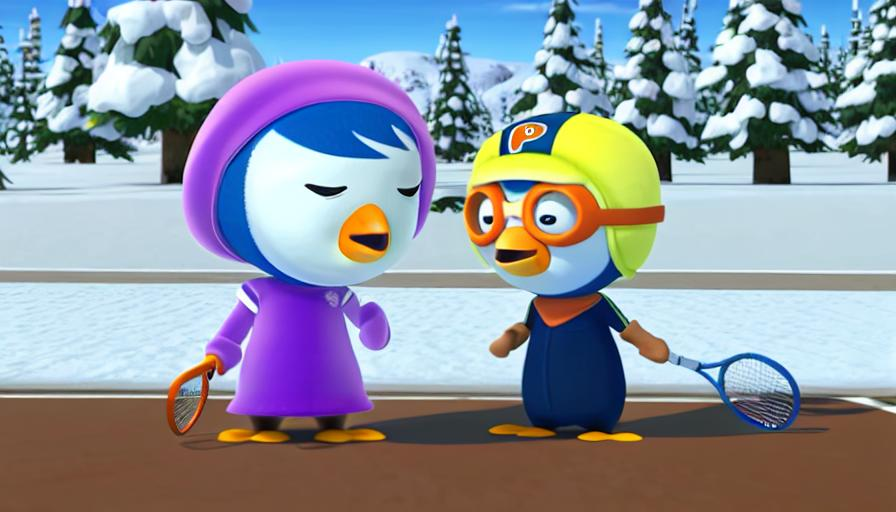

output/Pororo/sample/03000.jpg


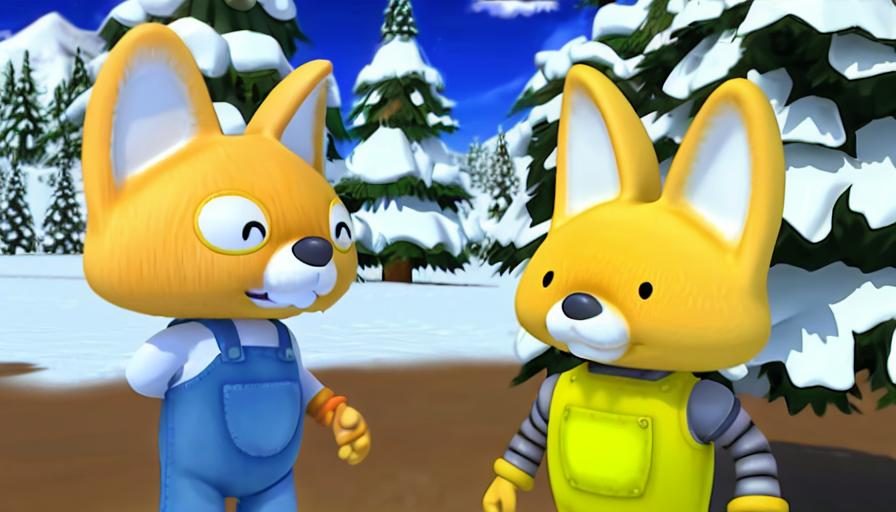


### Anh kiem tra tu eval_train
output/Pororo/test/03000/00001.jpg


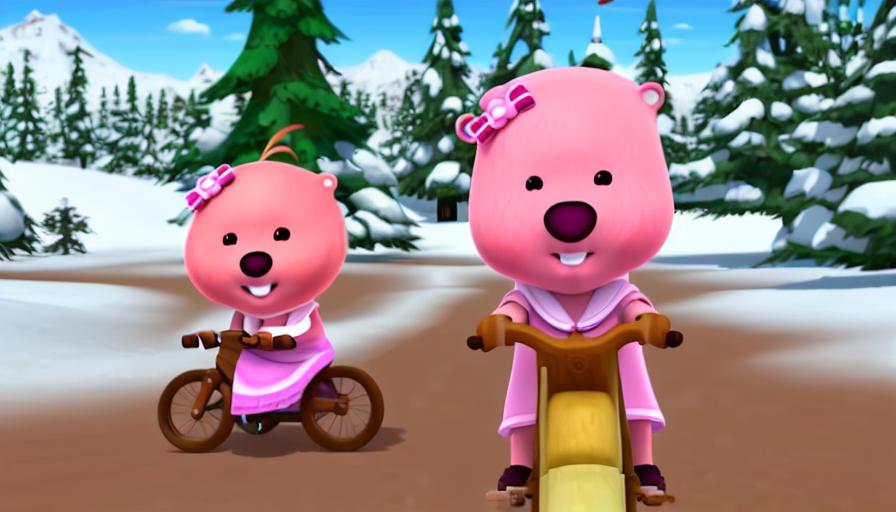

output/Pororo/test/03000/00002.jpg


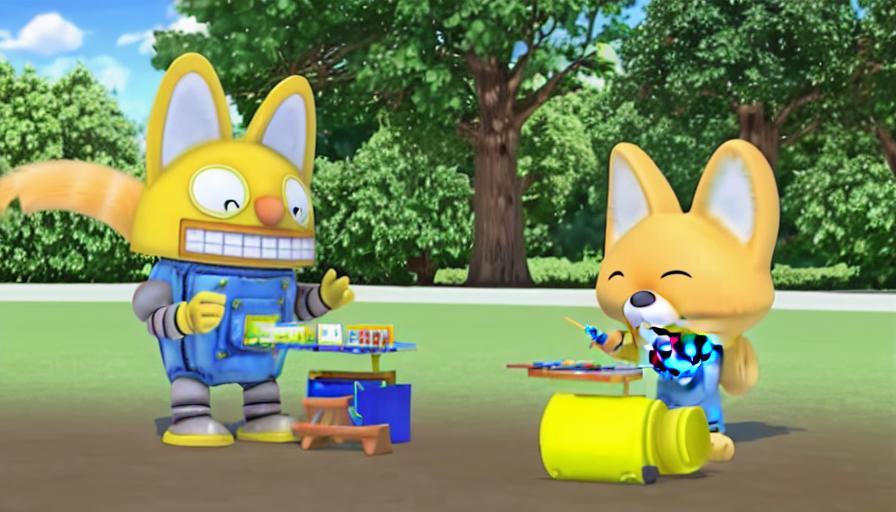

output/Pororo/test/03000/00003.jpg


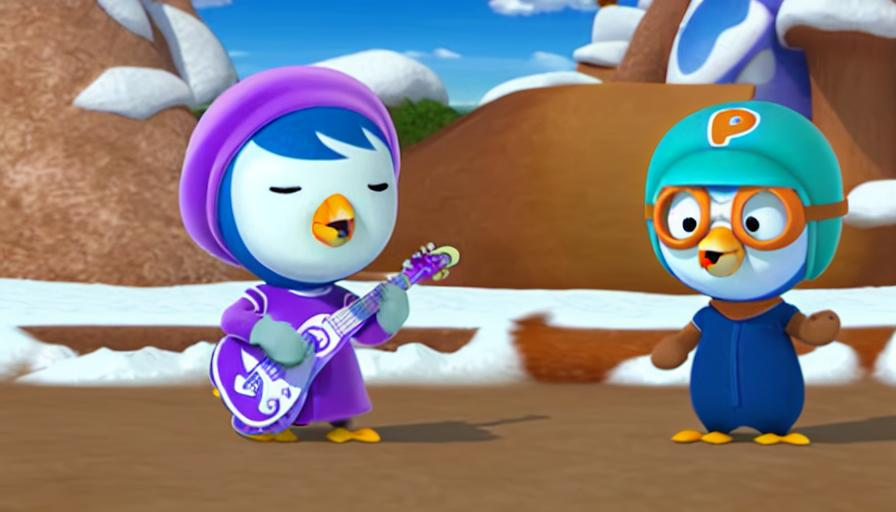


### Truyen moi da sample
sample/seed_655/story.jpg


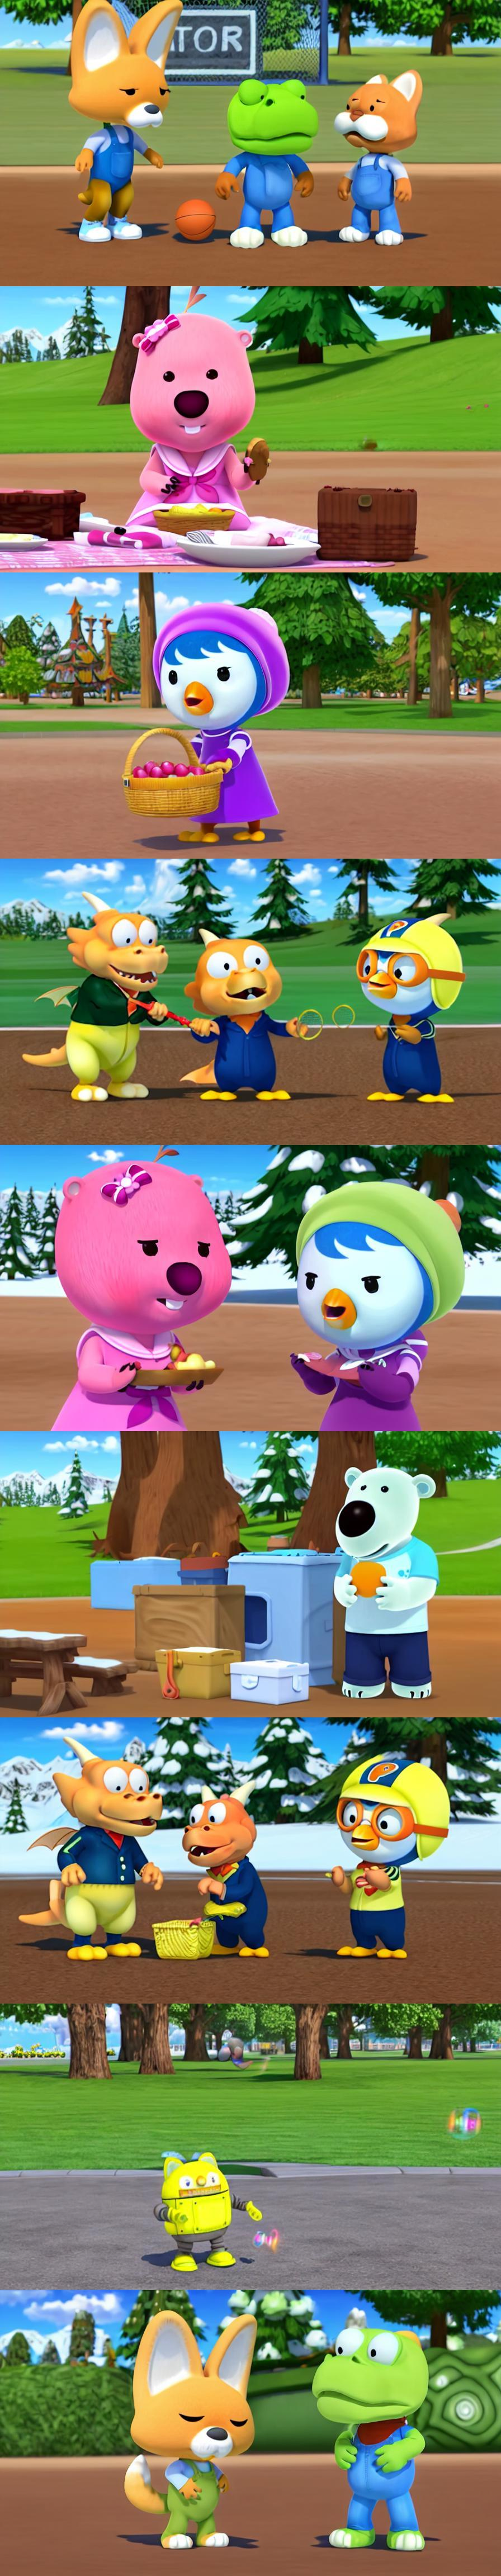


Da nen ket qua -> /kaggle/working/storyweaver_results.zip (2.6 MB)

Dung luong cac thu muc output:
  /kaggle/working/output/Pororo            3.20 GB
  /kaggle/working/sample                   0.00 GB


In [ ]:
# === 9. XEM KET QUA & DONG GOI ===
from IPython.display import display, Image as IPImage

def show(paths, max_w=1100, title=""):
    paths = [p for p in paths if p and os.path.isfile(p)]
    if not paths:
        print("(khong co anh:", title, ")"); return
    if title:
        print("\n### " + title)
    for p in paths:
        print(os.path.relpath(p, "/kaggle/working") if p.startswith("/kaggle") else p)
        display(IPImage(filename=p, width=max_w))


show(sorted(glob(os.path.join(CFG.SAMPLE_SUBDIR, "*.jpg")))[-2:],
     title="Anh kiem tra tu tap train (trong luc train)")
show(sorted(glob(os.path.join(CFG.TEST_SUBDIR, "*", "*.jpg")))[-3:],
     title="Anh kiem tra tu eval_train")
show(sorted(glob(os.path.join(CFG.SAMPLE_DIR, "seed_*", "story.jpg"))),
     title="Truyen moi da sample")

# --- dong goi (chi anh + text, khong kem checkpoint nang) ---
import zipfile
zip_path = "/kaggle/working/storyweaver_results.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for root in [CFG.SAMPLE_SUBDIR, CFG.TEST_SUBDIR, CFG.SAMPLE_DIR]:
        for dirpath, _, files in os.walk(root):
            for fn in files:
                if fn.lower().endswith((".jpg", ".png", ".txt", ".json")):
                    fp = os.path.join(dirpath, fn)
                    z.write(fp, os.path.relpath(fp, "/kaggle/working"))
    lh = os.path.join(CFG.OUTPUT_DIR, "loss_history.json")
    if os.path.isfile(lh):
        z.write(lh, os.path.relpath(lh, "/kaggle/working"))
print("\nDa nen ket qua ->", zip_path, "(%.1f MB)" % (os.path.getsize(zip_path) / 2**20))

print("\nDung luong cac thu muc output:")
for root in [CFG.OUTPUT_DIR, CFG.SAMPLE_DIR]:
    tot = sum(os.path.getsize(os.path.join(d, f))
              for d, _, fs in os.walk(root) for f in fs)
    print("  %-40s %.2f GB" % (root, tot / 2**30))

In [ ]:
!cp -R /kaggle/working /content/drive/MyDrive/DLDT/

In [ ]:
!rsync -rvP --progress /content/drive/MyDrive/DLDT/working /kaggle/working/checkpoint

sending incremental file list
created directory /kaggle/working/checkpoint
working/
working/storyweaver_results.zip
      2,740,536 100%  215.19MB/s    0:00:00 (xfr#1, to-chk=100/102)
working/output/
working/output/Pororo/
working/output/Pororo/loss_history.json
         85,641 100%  179.47kB/s    0:00:00 (xfr#2, to-chk=96/102)
working/output/Pororo/pipeline/
working/output/Pororo/pipeline/k_encoder.pt
        400,995 100%  408.76kB/s    0:00:00 (xfr#3, to-chk=92/102)
working/output/Pororo/pipeline/sw_meta.json
            208 100%    0.14kB/s    0:00:01 (xfr#4, to-chk=91/102)
working/output/Pororo/pipeline/unet/
working/output/Pororo/pipeline/unet/config.json
          1,845 100%    0.00kB/s    0:00:00 (xfr#5, to-chk=89/102)
working/output/Pororo/pipeline/unet/diffusion_pytorch_model.safetensors
  3,438,167,536 100%   25.24MB/s    0:02:09 (xfr#6, to-chk=88/102)
working/output/Pororo/sample/
working/output/Pororo/sample/00500.jpg
         45,186 100%   34.77kB/s    0:00:01 (xfr#7, to-c

## 10. So sánh hiệu quả với các phương pháp khác (giao thức của paper arXiv 2412.07375)

| Khía cạnh | Metric |
|---|---|
| Giữ danh tính (single-char) | DINO-I, CLIP-I |
| Bám ngữ nghĩa văn bản | CLIP-T |
| Toàn vẹn nhân vật (multi-char) | C-F1, F-Acc |
| Hiệu quả lưu trữ | #Params / dung lượng checkpoint |

DreamBooth / LoRA / Mix-of-Show / LoRA-Composer đều phải train một model riêng cho từng
nhân vật, không kịp trong một session Kaggle. Nên các cell dưới đo 4 đường chạy được ngay
từ checkpoint, không train lại gì:

1. `storyweaver` — checkpoint của bạn, đủ C-CG + KE-SG
2. `wo_kesg` — cùng checkpoint, tắt spatial guidance (ablation của paper)
3. `sd15_ccg` — SD1.5 gốc + caption Character-Graph, không train
4. `sd15_coarse` — SD1.5 gốc + caption thô = đường `w/o C-CG & KE-SG` trong Tab.3

cộng IP-Adapter (base/plus) ở cell tuỳ chọn. Còn lại lấy số công bố ở Tab.1/Tab.4 làm mốc.


## Config đánh giá

In [ ]:
import types, json, os, gc, time, re, shutil
from glob import glob

EVAL = types.SimpleNamespace(

    # ------------------------------------------------------------- CHECKPOINT
    # None = dung CFG.PIPELINE_DIR (ket qua train trong session nay).
    # Neu checkpoint nam o Input dataset cua session truoc thi tro tay vao day,
    # vi du: "/kaggle/input/storyweaver-out/output/Pororo/pipeline"
    CKPT_DIR = "/kaggle/working/checkpoint/working/output/Pororo/pipeline",

    # ------------------------------------------------------------- CHAY GI
    # storyweaver  : model da train (C-CG + KE-SG)          <- phuong phap cua notebook
    # wo_kesg      : model da train nhung tat spatial guidance (mask = 1)  <- ablation cua paper
    # sd15_ccg     : SD1.5 GOC + caption Character-Graph day du (khong train)
    # sd15_coarse  : SD1.5 GOC + caption tho (chi nhan lop: "gentoo penguin")
    #                = duong "w/o C-CG & KE-SG" trong Tab.3 cua paper
    METHODS = ["storyweaver", "wo_kesg", "sd15_ccg", "sd15_coarse"],
    TASKS   = ["single", "multi"],

    # ------------------------------------------------------------- QUY MO
    # Paper: 5 truyen/nhan vat (single) + 10 truyen (multi), 9 canh/truyen, 5 anh/canh.
    # Tren Kaggle nen giam xuong. Uoc luong: 1 anh ~ 25s o 50 step / T4.
    N_STORIES_SINGLE = 3,
    N_STORIES_MULTI  = 3,
    MAX_FRAMES       = 9,
    N_SEEDS          = 1,          # = "so anh moi canh" trong paper (paper dung 5)
    NUM_INFER_STEPS  = 50,         # paper: 100. Giam de kip thoi gian; DUNG CHUNG cho moi method
    GUIDANCE_SCALE   = 5.0,        # paper: 5.0
    SCALE            = 2.5,        # alpha cua KE-SG luc suy luan (paper: 2.5 Pororo, 1.0 Frozen)

    # ------------------------------------------------------------- METRIC
    CLIP_MODEL    = "openai/clip-vit-base-patch32",   # paper dung ViT-B/32
    DINO_MODEL    = "facebook/dinov2-giant",          # paper dung ViT-G/14
    DINO_FALLBACK = "facebook/dinov2-base",           # neu het VRAM / tai loi
    DINO_THRESH   = 0.5,           # nguong nhan dien nhan vat (paper: 0.5) - xem cell 10d
    CROP_MODE     = "tiles",       # "tiles" = cat anh thanh dai ngang roi phan loai tung dai
                                   # "global" = phan loai ca anh (sat chu paper nhung
                                   #            khong the phat hien >1 nhan vat)

    # ------------------------------------------------------------- KHAC
    OUT_DIR         = "/kaggle/working/compare",
    TIME_BUDGET_MIN = 300,         # tu dong dung sinh anh sau N phut
    OVERWRITE       = False,       # False = bo qua anh da co -> chay tiep duoc sau khi het gio
)

if EVAL.CKPT_DIR is None:
    EVAL.CKPT_DIR = CFG.PIPELINE_DIR
EVAL.IMG_DIR = os.path.join(EVAL.OUT_DIR, "images")
os.makedirs(EVAL.IMG_DIR, exist_ok=True)

_ok = os.path.isdir(os.path.join(EVAL.CKPT_DIR, "unet"))
print("CKPT_DIR :", EVAL.CKPT_DIR, "(co unet/:", _ok, ")")
if not _ok:
    print("  !! Khong thay unet/ -> cac method 'storyweaver' / 'wo_kesg' se bi bo qua.")
    EVAL.METHODS = [m for m in EVAL.METHODS if m not in ("storyweaver", "wo_kesg")]
if not CFG.FAST_SELF_ATTENTION:
    print("  !! CFG.FAST_SELF_ATTENTION = False -> AttnProcessor2_0 da bi patch toan cuc,")
    print("     SD1.5 goc khong chay duoc trong session nay. Bo cac method sd15_*.")
    print("     Muon chay chung: dat FAST_SELF_ATTENTION = True roi restart notebook.")
    EVAL.METHODS = [m for m in EVAL.METHODS if not m.startswith("sd15")]
print("METHODS  :", EVAL.METHODS)
print("TASKS    :", EVAL.TASKS)
print("Uoc tinh so anh phai sinh: <= %d"
      % (len(EVAL.METHODS) * ((EVAL.N_STORIES_SINGLE if "single" in EVAL.TASKS else 0)
                              + (EVAL.N_STORIES_MULTI if "multi" in EVAL.TASKS else 0))
         * EVAL.MAX_FRAMES * EVAL.N_SEEDS))

CKPT_DIR : /kaggle/working/checkpoint/working/output/Pororo/pipeline (co unet/: True )
METHODS  : ['storyweaver', 'wo_kesg', 'sd15_ccg', 'sd15_coarse']
TASKS    : ['single', 'multi']
Uoc tinh so anh phai sinh: <= 216


## Đề thi + caption cho từng phương pháp

In [ ]:
# Moi "frame" gom:
#   raw     : dong goc trong file truyen, con nguyen placeholder <Pororo>, <style>
#   ccg     : caption Character-Graph day du (storyweaver / wo_kesg / sd15_ccg)
#   coarse  : caption chi co nhan lop tho (sd15_coarse), va lam text tham chieu chung
#             khi tinh CLIP-T de moi method duoc cham tren cung mot cau
#   chars   : danh sach nhan vat BAT BUOC xuat hien -> dung cho C-F1 / F-Acc

_STYLE_TEXT = _read_first_line(CFG.STYLE_FILE) if os.path.isfile(CFG.STYLE_FILE) else ""
_CHAR_DESC = {}
for _f in sorted(glob(os.path.join(CFG.CHARACTER_DIR, "*.txt"))):
    _n = os.path.splitext(os.path.basename(_f))[0]
    if _n in CHAR_CLASS[CFG.DATA_NAME]:
        _CHAR_DESC[_n] = _read_first_line(_f)
print("Nhan vat co mo ta:", sorted(_CHAR_DESC))


def required_chars(raw_line):
    """Cac nhan vat duoc yeu cau trong 1 khung truyen (doc tu placeholder <Ten>)."""
    known = CHAR_CLASS[CFG.DATA_NAME]
    out = []
    for tag in re.findall(r"<(.*?)>", raw_line):
        if tag in known and tag not in out:
            out.append(tag)
    return out


def caption_ccg(raw_line):
    """Caption day du: <style> -> style.txt, <Ten> -> character/<Ten>.txt (C-CG)."""
    text = raw_line.replace("<style>", _STYLE_TEXT)
    for tag in re.findall(r"<(.*?)>", text):
        if tag in _CHAR_DESC:
            text = text.replace("<%s>" % tag, _CHAR_DESC[tag])
    return text


def caption_coarse(raw_line):
    """Caption tho: <Ten> -> nhan lop ('gentoo penguin'), giu style. = 'w/o C-CG'."""
    known = CHAR_CLASS[CFG.DATA_NAME]
    text = raw_line.replace("<style>", _STYLE_TEXT)
    for tag in re.findall(r"<(.*?)>", text):
        if tag in known:
            text = text.replace("<%s>" % tag, known[tag])
    return text


def list_eval_stories(task, limit):
    """Lay cac file truyen trong eval_new_story. Single: rai deu tren cac nhan vat."""
    root = CFG.NEW_STORY_DIR
    if task == "single":
        pats = [os.path.join(root, "Single", "*", "*.txt"),
                os.path.join(root, "single", "*", "*.txt")]
    else:
        pats = [os.path.join(root, "Multi", "all", "*.txt"),
                os.path.join(root, "Multi", "*", "*.txt"),
                os.path.join(root, "multi", "*", "*.txt")]
    files = []
    for p in pats:
        files = sorted(glob(p))
        if files:
            break
    if not files:
        print("  !! Khong thay truyen '%s' trong %s" % (task, root))
        return []
    if task == "single":                       # round-robin theo thu muc nhan vat
        by_dir = {}
        for f in files:
            by_dir.setdefault(os.path.dirname(f), []).append(f)
        picked, i = [], 0
        while len(picked) < limit:
            added = False
            for d in sorted(by_dir):
                if i < len(by_dir[d]):
                    picked.append(by_dir[d][i]); added = True
                    if len(picked) >= limit:
                        break
            if not added:
                break
            i += 1
        files = picked
    return files[:limit]


def load_story(path):
    """-> (story_id, [ {idx, raw, ccg, coarse, chars} ... ])"""
    with open(path, "r", encoding="utf-8") as f:
        lines = [ln.strip() for ln in f if ln.strip()]
    lines = lines[:EVAL.MAX_FRAMES]
    sid = "%s__%s" % (os.path.basename(os.path.dirname(path)),
                      os.path.splitext(os.path.basename(path))[0])
    frames = [{"idx": i, "raw": ln, "ccg": caption_ccg(ln),
               "coarse": caption_coarse(ln), "chars": required_chars(ln)}
              for i, ln in enumerate(lines)]
    return sid, frames


EVAL_SET = {}
for _task in EVAL.TASKS:
    _lim = EVAL.N_STORIES_SINGLE if _task == "single" else EVAL.N_STORIES_MULTI
    EVAL_SET[_task] = []
    for _p in list_eval_stories(_task, _lim):
        _sid, _fr = load_story(_p)
        if _fr:
            EVAL_SET[_task].append({"path": _p, "sid": _sid, "frames": _fr})
    print("[%s] %d truyen, %d khung"
          % (_task, len(EVAL_SET[_task]), sum(len(s["frames"]) for s in EVAL_SET[_task])))

# In thu 1 mau de mat thuong kiem tra
for _task in EVAL.TASKS:
    if EVAL_SET[_task]:
        _f = EVAL_SET[_task][0]["frames"][0]
        print("\n--- vi du (%s) ---" % _task)
        print("chars :", _f["chars"])
        print("coarse:", _f["coarse"][:200])
        print("ccg   :", _f["ccg"][:200], "...")
        break


# ---------------------------------------------------------------------------
# Vong sampling cho SD1.5 GOC (encoder_hidden_states la tensor, khong co mask).
# Dung y het scheduler / guidance / seed / so buoc voi validation() de so sanh cong bang.
# ---------------------------------------------------------------------------
@torch.no_grad()
def validation_plain(prompts, tokenizer, text_encoder, unet, vae, device,
                     guidance_scale=5.0, seed=None, num_steps=100,
                     height=None, width=None, autocast_dtype=None):
    height = height or CFG.RESOLUTION
    width = width or CFG.WIDTH
    lat_h, lat_w = height // 8, width // 8
    scheduler = LMSDiscreteScheduler(beta_start=0.00085, beta_end=0.012,
                                     beta_schedule="scaled_linear", num_train_timesteps=1000)
    bsz = len(prompts)
    ids = tokenizer(list(prompts), padding="max_length", truncation=True,
                    max_length=tokenizer.model_max_length, return_tensors="pt").input_ids
    cond = text_encoder(ids.to(device), return_dict=False)[0]
    unc_ids = tokenizer([""] * bsz, padding="max_length", truncation=True,
                        max_length=tokenizer.model_max_length, return_tensors="pt").input_ids
    unc = text_encoder(unc_ids.to(device), return_dict=False)[0]

    gen = torch.manual_seed(seed) if seed is not None else None
    latents = torch.randn((bsz, unet.config.in_channels, lat_h, lat_w), generator=gen)
    latents = latents.to(cond)
    scheduler.set_timesteps(num_steps)
    latents = latents * scheduler.init_noise_sigma

    ac = (torch.autocast(device_type="cuda", dtype=autocast_dtype)
          if (autocast_dtype is not None and torch.cuda.is_available()) else nullcontext())
    for t in scheduler.timesteps:
        lm = scheduler.scale_model_input(latents, t)
        with ac:
            n_t = unet(lm, t, encoder_hidden_states=cond).sample.float()
            n_u = unet(lm, t, encoder_hidden_states=unc).sample.float()
        latents = scheduler.step(n_u + guidance_scale * (n_t - n_u), t,
                                 latents.float()).prev_sample
    with ac:
        images = vae.decode((1 / 0.18215 * latents).to(next(vae.parameters()).dtype)).sample
    return [th2image(im) for im in images]


class OnesKEncoder(nn.Module):
    """Thay Autok_encoder bang mask toan 1 -> processor bo qua -> TAT KE-SG.
    Dung de tao duong 'w/o KE-SG' trong bang ablation cua paper."""

    def __init__(self, H, W):
        super().__init__()
        self.H, self.W = H, W

    def set_scale(self, scale=1.0):
        pass

    def forward(self, char_input_ids, char_indice_list, prior_means, prior_cors,
                text_encoder, timesteps):
        bs = char_input_ids[0].shape[0]
        m = torch.ones(bs, self.H, self.W)
        return [m] * len(char_input_ids), [], [], []


print("\nDa chuan bi de thi + validation_plain() + OnesKEncoder()")

Nhan vat co mo ta: ['Crong', 'Eddy', 'Harry', 'Loopy', 'Petty', 'Poby', 'Pororo', 'Rody', 'Tongtong']
[single] 3 truyen, 27 khung
[multi] 3 truyen, 27 khung

--- vi du (single) ---
chars : ['Crong']
coarse: 2.5D cartoon style. A dinosaur entered a vibrant park, surrounded by lush green trees and colorful flowers. dinosaur
ccg   : 2.5D cartoon style. A dinosaur entered a vibrant park, surrounded by lush green trees and colorful flowers. This green dinosaur wears a blue jumpsuit and a red bandana and red gloves. ...

Da chuan bi de thi + validation_plain() + OnesKEncoder()


## Sinh ảnh cho từng phương pháp

In [ ]:
# Moi method chay 1 luot roi giai phong VRAM. Anh duoc cache ra dia theo duong dan
#   compare/images/<method>/<task>/<story_id>/s<seed>_f<frame>.jpg
# => het gio Kaggle van chay tiep duoc (OVERWRITE=False se bo qua anh da co).

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
AUTOCAST = torch.float16 if CFG.MIXED_PRECISION == "fp16" else None

random.seed(CFG.SEED)
EVAL_SEEDS = random.sample(range(1, 1024), EVAL.N_SEEDS)
print("Seed dung chung cho moi method:", EVAL_SEEDS)


def _img_path(method, task, sid, seed, fi):
    d = os.path.join(EVAL.IMG_DIR, method, task, sid)
    os.makedirs(d, exist_ok=True)
    return os.path.join(d, "s%d_f%02d.jpg" % (seed, fi))


def _free(*objs):
    for o in objs:
        try:
            del o
        except Exception:
            pass
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def _load_eval_unet(method):
    """Tra ve (unet, k_encoder or None). storyweaver/wo_kesg -> checkpoint da train."""
    if method in ("storyweaver", "wo_kesg"):
        u = UNet2DConditionModel.from_pretrained(EVAL.CKPT_DIR, subfolder="unet")
        u = set_layer_with_name_and_path(u)
        if method == "storyweaver":
            ke = load_k_encoder(os.path.join(EVAL.CKPT_DIR, "k_encoder.pt"),
                                scale=EVAL.SCALE)
        else:
            ke = OnesKEncoder(CFG.RESOLUTION, CFG.WIDTH)
        ke = ke.to(DEVICE, dtype=torch.float32).eval()
        ke.requires_grad_(False)
    else:                                    # SD1.5 goc, KHONG patch attention
        u = UNet2DConditionModel.from_pretrained(CFG.PRETRAINED_MODEL, subfolder="unet")
        ke = None
    u.requires_grad_(False)
    u = u.to(DEVICE, dtype=torch.float32).eval()
    return u, ke


def generate_for_method(method, deadline):
    n_new, n_skip = 0, 0
    u, ke = _load_eval_unet(method)
    text_encoder.to(DEVICE, dtype=torch.float32)
    vae.to(DEVICE, dtype=torch.float32)

    for task in EVAL.TASKS:
        for story in EVAL_SET[task]:
            sid, frames = story["sid"], story["frames"]

            # --- 2 nhanh: dung validation() (co mask) hay validation_plain() ---
            if method in ("storyweaver", "wo_kesg"):
                ds = TBC_Bench_Single_Story(
                    data_root=story["path"], tokenizer=tokenizer,
                    resolution=CFG.RESOLUTION, caption_dir=CFG.CHARACTER_DIR,
                    max_char=CFG.MAX_CHAR, style_dir=CFG.STYLE_FILE, type=CFG.DATA_NAME)
                dl = torch.utils.data.DataLoader(ds, shuffle=False, batch_size=1, num_workers=0)
                batches = list(dl)[:len(frames)]
            else:
                batches = None

            for seed in EVAL_SEEDS:
                for fi, fr in enumerate(frames):
                    p = _img_path(method, task, sid, seed, fi)
                    if os.path.isfile(p) and not EVAL.OVERWRITE:
                        n_skip += 1
                        continue
                    if time.time() > deadline:
                        print("  !! het ngan sach thoi gian -> dung o", method, task, sid)
                        _free(u, ke)
                        return n_new, n_skip, True

                    if batches is not None:
                        b = dict(batches[fi])
                        b["input_ids"] = b["input_ids"].to(DEVICE)
                        imgs, _ = validation(
                            b, tokenizer, text_encoder, u, vae, ke, DEVICE,
                            guidance_scale=EVAL.GUIDANCE_SCALE, seed=seed,
                            num_steps=EVAL.NUM_INFER_STEPS, height=CFG.RESOLUTION,
                            width=CFG.WIDTH, autocast_dtype=AUTOCAST, progress=False)
                    else:
                        prompt = fr["ccg"] if method == "sd15_ccg" else fr["coarse"]
                        imgs = validation_plain(
                            [prompt], tokenizer, text_encoder, u, vae, DEVICE,
                            guidance_scale=EVAL.GUIDANCE_SCALE, seed=seed,
                            num_steps=EVAL.NUM_INFER_STEPS, height=CFG.RESOLUTION,
                            width=CFG.WIDTH, autocast_dtype=AUTOCAST)
                    imgs[0].save(p, quality=95)
                    n_new += 1
            print("  [%s/%s] %s -> xong" % (method, task, sid))

    _free(u, ke)
    return n_new, n_skip, False


# --- luu metadata de cell tinh metric doc lai (khong phai sinh anh lai) -----
META = {"seeds": EVAL_SEEDS, "tasks": {}}
for task in EVAL.TASKS:
    META["tasks"][task] = [{"sid": s["sid"], "path": s["path"],
                            "frames": [{"idx": f["idx"], "chars": f["chars"],
                                        "coarse": f["coarse"], "ccg": f["ccg"]}
                                       for f in s["frames"]]}
                           for s in EVAL_SET[task]]
with open(os.path.join(EVAL.OUT_DIR, "meta.json"), "w", encoding="utf-8") as f:
    json.dump(META, f, ensure_ascii=False, indent=1)

_deadline = time.time() + EVAL.TIME_BUDGET_MIN * 60
for _m in EVAL.METHODS:
    print("\n" + "=" * 60 + "\nSINH ANH: %s" % _m)
    _t0 = time.time()
    _new, _skip, _stopped = generate_for_method(_m, _deadline)
    print("  moi: %d | bo qua (da co): %d | %.1f phut"
          % (_new, _skip, (time.time() - _t0) / 60))
    if _stopped:
        print("  -> chay lai cell nay o session sau de sinh not (anh cu duoc giu lai)")
        break

print("\nAnh nam trong:", EVAL.IMG_DIR)

Seed dung chung cho moi method: [655]

SINH ANH: storyweaver
[story] 9 khung | /root/TBC_Bench/eval-plot/eval_new_story/Pororo_the_Little_Penguin/Single/Crong/1.txt
  [storyweaver/single] Crong__1 -> xong
[story] 9 khung | /root/TBC_Bench/eval-plot/eval_new_story/Pororo_the_Little_Penguin/Single/Eddy/1.txt
  [storyweaver/single] Eddy__1 -> xong
[story] 9 khung | /root/TBC_Bench/eval-plot/eval_new_story/Pororo_the_Little_Penguin/Single/Harry/1.txt
  [storyweaver/single] Harry__1 -> xong
[story] 9 khung | /root/TBC_Bench/eval-plot/eval_new_story/Pororo_the_Little_Penguin/Multi/all/1.txt
  [storyweaver/multi] all__1 -> xong
[story] 9 khung | /root/TBC_Bench/eval-plot/eval_new_story/Pororo_the_Little_Penguin/Multi/all/10.txt
  [storyweaver/multi] all__10 -> xong
[story] 9 khung | /root/TBC_Bench/eval-plot/eval_new_story/Pororo_the_Little_Penguin/Multi/all/2.txt
  [storyweaver/multi] all__2 -> xong
  moi: 54 | bo qua (da co): 0 | 21.0 phut

SINH ANH: wo_kesg
[story] 9 khung | /root/TBC_Benc

## Mô hình đo + ngân hàng đặc trưng + hiệu chỉnh ngưỡng

In [ ]:
# Metric theo dung dinh nghia trong paper (muc "Evaluation Metric"):
#   DINO-I  : cos-sim dac trung DINO giua anh sinh ra va tap anh GT cua nhan vat
#   CLIP-I  : nhu tren nhung dung CLIP ViT-B/32
#   CLIP-T  : cos-sim giua anh sinh ra va caption
#   C-F1    : ti le nhan vat trong anh khop dung voi nhan vat trong prompt
#   F-Acc   : ti le khung co DU tat ca nhan vat duoc yeu cau
# C-F1 / F-Acc dung DINO lam bo phan loai, nguong 0.5 (paper).

# Giai phong VRAM cua SD truoc khi nap DINOv2-giant (~4.4 GB)
for _n in ["unet", "trained_unet", "text_encoder", "vae"]:
    if _n in globals() and hasattr(globals()[_n], "to"):
        try:
            globals()[_n].to("cpu")
        except Exception:
            pass
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

from transformers import CLIPModel, CLIPProcessor, AutoModel, AutoImageProcessor


class Embedder:
    def __init__(self, device=None):
        self.device = device or ("cuda" if torch.cuda.is_available() else "cpu")
        print("Nap CLIP:", EVAL.CLIP_MODEL)
        self.clip = CLIPModel.from_pretrained(EVAL.CLIP_MODEL).to(self.device).eval()
        self.clip_proc = CLIPProcessor.from_pretrained(EVAL.CLIP_MODEL)
        for name in [EVAL.DINO_MODEL, EVAL.DINO_FALLBACK]:
            try:
                print("Nap DINO:", name)
                self.dino = AutoModel.from_pretrained(name).to(self.device).eval()
                self.dino_proc = AutoImageProcessor.from_pretrained(name)
                self.dino_name = name
                break
            except Exception as e:
                print("   that bai:", type(e).__name__, str(e)[:150])
                self.dino = None
        assert self.dino is not None, "Khong nap duoc DINO"
        if self.dino_name != EVAL.DINO_MODEL:
            print("  !! Dang dung %s thay vi %s -> so tuyet doi KHONG so truc tiep"
                  " duoc voi bang trong paper (van so duoc GIUA cac method)."
                  % (self.dino_name, EVAL.DINO_MODEL))

    @torch.no_grad()
    def clip_image(self, pils, bs=16):
        out = []
        for i in range(0, len(pils), bs):
            inp = self.clip_proc(images=pils[i:i + bs], return_tensors="pt").to(self.device)
            f = self.clip.get_image_features(**inp)
            out.append(F.normalize(f.float(), dim=-1).cpu())
        return torch.cat(out)

    @torch.no_grad()
    def clip_text(self, texts, bs=16):
        out = []
        for i in range(0, len(texts), bs):
            inp = self.clip_proc(text=texts[i:i + bs], return_tensors="pt",
                                 padding=True, truncation=True, max_length=77).to(self.device)
            f = self.clip.get_text_features(input_ids=inp["input_ids"],
                                            attention_mask=inp["attention_mask"])
            out.append(F.normalize(f.float(), dim=-1).cpu())
        return torch.cat(out)

    @torch.no_grad()
    def dino_image(self, pils, bs=8):
        out = []
        for i in range(0, len(pils), bs):
            inp = self.dino_proc(images=pils[i:i + bs], return_tensors="pt").to(self.device)
            f = self.dino(**inp).last_hidden_state[:, 0]      # token CLS
            out.append(F.normalize(f.float(), dim=-1).cpu())
        return torch.cat(out)


EMB = Embedder()

# --- ngan hang anh GT cua tung nhan vat (train-folder/<world>/image/<Ten>/*) -----
REF = {"clip": {}, "dino": {}, "files": {}}
for _c in sorted(CHAR_CLASS[CFG.DATA_NAME]):
    _fs = sorted(sum([glob(os.path.join(CFG.TRAIN_DIR, "image", _c, "*." + e))
                      for e in IMG_EXTS], []))
    if not _fs:
        continue
    _ims = [Image.open(p).convert("RGB") for p in _fs]
    REF["files"][_c] = _fs
    REF["clip"][_c] = EMB.clip_image(_ims)
    REF["dino"][_c] = EMB.dino_image(_ims)
    print("  %-10s %d anh tham chieu" % (_c, len(_fs)))
CHARS = sorted(REF["dino"])


def char_scores(dino_emb):
    """(n, d) -> (n, n_char): diem trung binh voi tap anh GT cua tung nhan vat."""
    return torch.stack([(dino_emb @ REF["dino"][c].T).mean(dim=1) for c in CHARS], dim=1)


# --- hieu chinh nguong: so sanh phan bo diem cung-nhan-vat vs khac-nhan-vat -----
def calibrate_threshold():
    intra, inter = [], []
    for ci, c in enumerate(CHARS):
        bank = REF["dino"][c]
        if len(bank) < 2:
            continue
        for k in range(len(bank)):
            q = bank[k:k + 1]
            same = torch.cat([bank[:k], bank[k + 1:]])
            intra.append(float((q @ same.T).mean()))
            for c2 in CHARS:
                if c2 != c:
                    inter.append(float((q @ REF["dino"][c2].T).mean()))
    if not intra or not inter:
        return None
    intra_t = torch.tensor(intra); inter_t = torch.tensor(inter)
    print("\nHieu chinh nguong nhan dien (%s):" % EMB.dino_name)
    print("  cung nhan vat : trung binh %.3f | phan vi 10%% %.3f"
          % (intra_t.mean(), intra_t.quantile(0.10)))
    print("  khac nhan vat : trung binh %.3f | phan vi 90%% %.3f"
          % (inter_t.mean(), inter_t.quantile(0.90)))
    best, best_acc = None, -1
    for th in torch.linspace(0.1, 0.9, 81):
        acc = ((intra_t >= th).float().mean() + (inter_t < th).float().mean()) / 2
        if acc > best_acc:
            best, best_acc = float(th), float(acc)
    print("  nguong tach tot nhat ~ %.2f (do chinh xac can bang %.1f%%) | dang dung %.2f"
          % (best, best_acc * 100, EVAL.DINO_THRESH))
    if abs(best - EVAL.DINO_THRESH) > 0.12:
        print("  !! Lech nhieu so voi 0.5 cua paper. Neu dung DINO khac ViT-G/14 thi nen"
              " dat EVAL.DINO_THRESH = %.2f roi chay lai cell 10e." % best)
    return best


_SUGGESTED_TH = calibrate_threshold()

Nap CLIP: openai/clip-vit-base-patch32


config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/605M [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

...

Nap DINO: facebook/dinov2-giant


config.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/4.55G [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/436 [00:00<?, ?B/s]

  Crong      12 anh tham chieu
  Eddy       11 anh tham chieu
  Harry      12 anh tham chieu
  Loopy      13 anh tham chieu
  Petty      13 anh tham chieu
  Poby       13 anh tham chieu
  Pororo     15 anh tham chieu
  Rody       12 anh tham chieu
  Tongtong   13 anh tham chieu

Hieu chinh nguong nhan dien (facebook/dinov2-giant):
  cung nhan vat : trung binh 0.626 | phan vi 10% 0.517
  khac nhan vat : trung binh 0.513 | phan vi 90% 0.595
  nguong tach tot nhat ~ 0.60 (do chinh xac can bang 81.2%) | dang dung 0.50


## Tính metric & lập bảng

In [ ]:
import pandas as pd

OWN_CAPTION = {"storyweaver": "ccg", "wo_kesg": "ccg", "sd15_ccg": "ccg",
               "sd15_coarse": "coarse", "ip_adapter": "coarse", "ip_adapter_plus": "coarse"}
NICE_NAME = {"storyweaver":     "StoryWeaver (notebook, C-CG + KE-SG)",
             "wo_kesg":         "  w/o KE-SG (tat spatial guidance)",
             "sd15_ccg":        "SD1.5 goc + caption C-CG (khong train)",
             "sd15_coarse":     "SD1.5 goc + caption tho (w/o C-CG & KE-SG)",
             "ip_adapter":      "IP-Adapter (base)",
             "ip_adapter_plus": "IP-Adapter (plus)"}

_TXT_CACHE = {}


def clip_text_cached(t):
    if t not in _TXT_CACHE:
        _TXT_CACHE[t] = EMB.clip_text([t])
    return _TXT_CACHE[t]


def detect_chars_in(img, n_req):
    """Tra ve {ten_nhan_vat: diem} phat hien duoc trong anh."""
    crops = [img]
    n = max(int(n_req), 1)
    if EVAL.CROP_MODE == "tiles" and n > 1:
        w, h = img.width, img.height
        for k in range(n):
            crops.append(img.crop((int(k * w / n), 0, int((k + 1) * w / n), h)))
    sc = char_scores(EMB.dino_image(crops))              # (n_crop, n_char)
    found = {}
    for r in range(sc.shape[0]):
        j = int(sc[r].argmax())
        s = float(sc[r, j])
        if s >= EVAL.DINO_THRESH:
            found[CHARS[j]] = max(found.get(CHARS[j], 0.0), s)
    return found


rows = []
for method in EVAL.METHODS:
    for task in EVAL.TASKS:
        for story in EVAL_SET[task]:
            sid = story["sid"]
            for seed in EVAL_SEEDS:
                for fi, fr in enumerate(story["frames"]):
                    p = _img_path(method, task, sid, seed, fi)
                    if not os.path.isfile(p):
                        continue
                    img = Image.open(p).convert("RGB")
                    req = fr["chars"]
                    ci = EMB.clip_image([img])
                    di = EMB.dino_image([img])
                    t_common = clip_text_cached(fr["coarse"])
                    t_own = clip_text_cached(fr[OWN_CAPTION.get(method, "coarse")])

                    r = {"method": method, "task": task, "story": sid, "seed": seed,
                         "frame": fi, "n_char": len(req),
                         "clip_t_common": float(ci @ t_common.T) * 100,
                         "clip_t_own": float(ci @ t_own.T) * 100}

                    if len(req) == 1 and req[0] in REF["dino"]:
                        c = req[0]
                        r["dino_i"] = float((di @ REF["dino"][c].T).mean()) * 100
                        r["clip_i"] = float((ci @ REF["clip"][c].T).mean()) * 100

                    found = detect_chars_in(img, len(req))
                    if req:
                        match = sum(1 for c in req if c in found)
                        r["c_f1"] = match / len(req) * 100
                        r["f_acc"] = 100.0 if match == len(req) else 0.0
                    rows.append(r)

RAW = pd.DataFrame(rows)
assert len(RAW), "Chua co anh nao - hay chay cell 10c truoc."
RAW.to_csv(os.path.join(EVAL.OUT_DIR, "per_image_metrics.csv"), index=False)
print("Da cham %d anh\n" % len(RAW))


def _table(task, cols):
    sub = RAW[RAW.task == task]
    if not len(sub):
        return None
    g = sub.groupby("method")[cols].mean().round(2)
    g["n_anh"] = sub.groupby("method").size()
    g = g.reindex([m for m in EVAL.METHODS if m in g.index])
    g.index = [NICE_NAME.get(m, m) for m in g.index]
    return g


TAB_SINGLE = _table("single", ["dino_i", "clip_i", "clip_t_common", "clip_t_own"])
TAB_MULTI = _table("multi", ["clip_t_common", "clip_t_own", "f_acc", "c_f1"])

if TAB_SINGLE is not None:
    print("=" * 78)
    print("SINGLE-CHARACTER  (%s, %d buoc, guidance %.1f)"
          % (CFG.DATA_NAME, EVAL.NUM_INFER_STEPS, EVAL.GUIDANCE_SCALE))
    print("=" * 78)
    print(TAB_SINGLE.rename(columns={"dino_i": "DINO-I", "clip_i": "CLIP-I",
                                     "clip_t_common": "CLIP-T(chung)",
                                     "clip_t_own": "CLIP-T(rieng)"}).to_string())
if TAB_MULTI is not None:
    print("\n" + "=" * 78)
    print("MULTI-CHARACTER")
    print("=" * 78)
    print(TAB_MULTI.rename(columns={"clip_t_common": "CLIP-T(chung)",
                                    "clip_t_own": "CLIP-T(rieng)",
                                    "f_acc": "F-Acc", "c_f1": "C-F1"}).to_string())

with open(os.path.join(EVAL.OUT_DIR, "summary.json"), "w", encoding="utf-8") as f:
    json.dump({"config": {k: v for k, v in vars(EVAL).items() if not k.startswith("_")},
               "dino_model": EMB.dino_name, "dino_thresh": EVAL.DINO_THRESH,
               "single": None if TAB_SINGLE is None else TAB_SINGLE.to_dict(),
               "multi": None if TAB_MULTI is None else TAB_MULTI.to_dict()},
              f, ensure_ascii=False, indent=1, default=str)

print("""
Doc bang the nao:
  CLIP-T(chung) : moi method deu cham tren CUNG mot caption tho -> so sanh cong bang.
  CLIP-T(rieng) : cham tren caption ma method do thuc su dung -> giong cach paper bao cao,
                  nhung caption C-CG dai hon nen co loi the.
  Chenh lech giua 2 cot chinh la phan "an theo prompt" chu khong phai do model tot hon.
""")

Da cham 216 anh

SINGLE-CHARACTER  (Pororo, 50 buoc, guidance 5.0)
                                            DINO-I  CLIP-I  CLIP-T(chung)  CLIP-T(rieng)  n_anh
StoryWeaver (notebook, C-CG + KE-SG)         60.34   84.49          29.55          33.28     27
  w/o KE-SG (tat spatial guidance)           57.70   83.39          29.96          33.62     27
SD1.5 goc + caption C-CG (khong train)       30.20   69.53          31.08          31.81     27
SD1.5 goc + caption tho (w/o C-CG & KE-SG)   28.22   66.75          33.34          33.34     27

MULTI-CHARACTER
                                            CLIP-T(chung)  CLIP-T(rieng)  F-Acc   C-F1  n_anh
StoryWeaver (notebook, C-CG + KE-SG)                29.65          33.22  62.96  74.07     27
  w/o KE-SG (tat spatial guidance)                  30.92          34.05  51.85  66.67     27
SD1.5 goc + caption C-CG (khong train)              32.31          33.94   0.00   0.00     27
SD1.5 goc + caption tho (w/o C-CG & KE-SG)          35.57   

## Đối chiếu với số công bố trong paper + biểu đồ

So tham so 1 luot sinh anh: 1017 M
   text_encoder     123.1 M
   vae_encoder       34.2 M
   unet             859.5 M
   k_encoder          0.1 M
Dung luong checkpoint: 3.20 GB (1 model dung cho TAT CA nhan vat)
So sanh: DreamBooth/LoRA can 1 model RIENG cho moi nhan vat -> x9

SINGLE-CHARACTER | Pororo
                                                Method  DINO-I  CLIP-I  CLIP-T  #Params (M)
      StoryWeaver (notebook, C-CG + KE-SG)  [do o day]   60.34   84.49   33.28         1017
          w/o KE-SG (tat spatial guidance)  [do o day]   57.70   83.39   33.62         1017
    SD1.5 goc + caption C-CG (khong train)  [do o day]   30.20   69.53   31.81         1017
SD1.5 goc + caption tho (w/o C-CG & KE-SG)  [do o day]   28.22   66.75   33.34         1017
                                     StoryGEN  [paper]   52.92   76.03   26.98         1064
                            IP-Adapter (base)  [paper]   48.85   76.66   29.98         1038
                            IP-Adapter (plus)  [pa

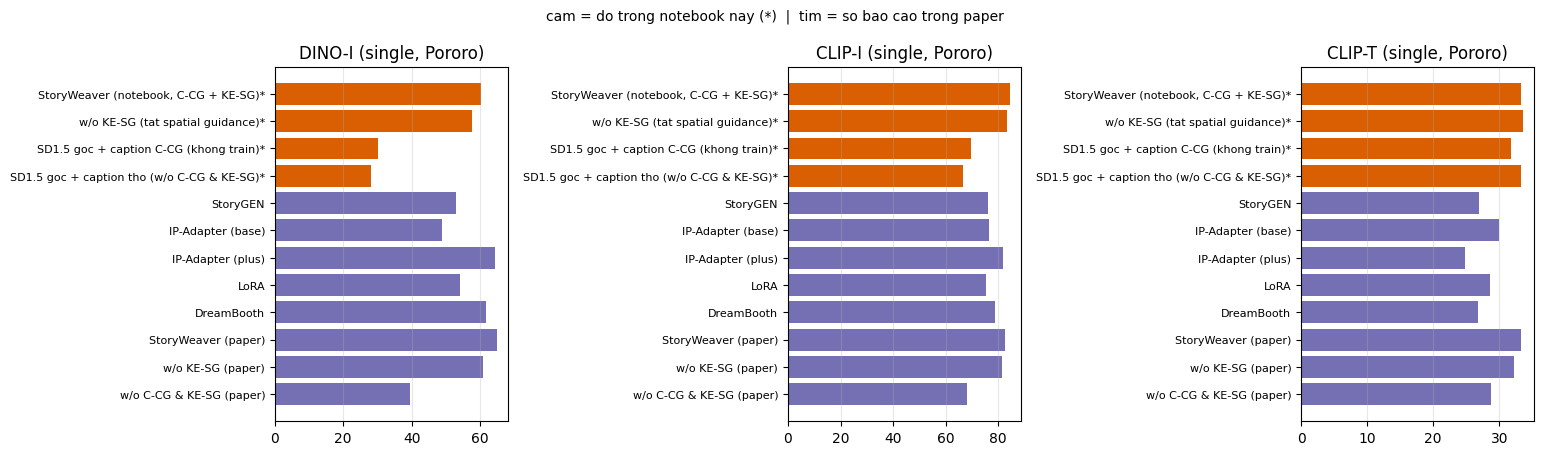

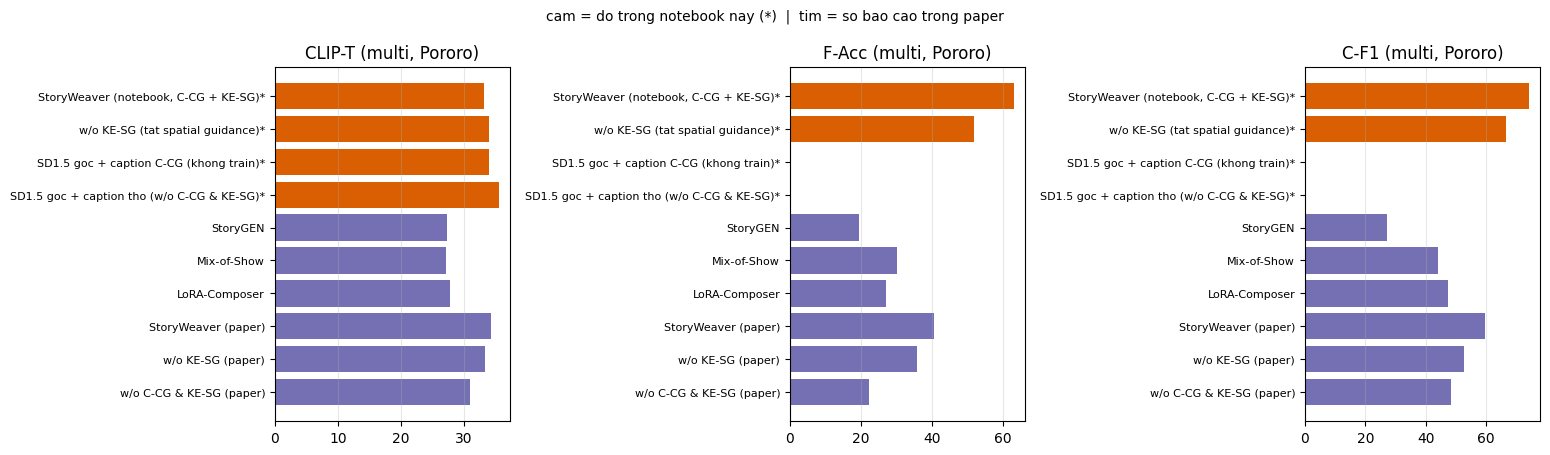


LUU Y KHI DIEN GIAI - cac so [do o day] va [paper] KHONG cung dieu kien:
  * notebook train 3000 step, paper train 20000 step
  * suy luan 50 buoc (paper 100), 1 anh/canh (paper 5), 3 truyen (paper 5/nhan vat + 10 multi)
  * DINO dang dung: facebook/dinov2-giant (paper: ViT-G/14), nguong C-F1 = 0.50
  * C-F1/F-Acc o day phat hien nhan vat theo che do 'tiles'; paper khong cong bo chi tiet
    cach cat vung nen con so tuyet doi co the lech.
Hay doc theo THU TU XEP HANG va do lech GIUA cac dong [do o day]; cot [paper] chi de biet
tran tren cua phuong phap khi train du.



In [ ]:
import matplotlib.pyplot as plt

# Bang 1 + Bang 4 cua paper. Day la so TAC GIA BAO CAO (20000 step, 100 buoc suy luan,
# 5 anh/canh, DINO ViT-G/14) - dung lam moc tham chieu, KHONG phai do lai o day.
PAPER = {
 "Pororo": {
  "single": {   # method: (DINO-I, CLIP-I, CLIP-T, #Params M)
    "StoryGEN":            (52.92, 76.03, 26.98, 1064),
    "IP-Adapter (base)":   (48.85, 76.66, 29.98, 1038),
    "IP-Adapter (plus)":   (64.36, 81.64, 24.88, 1063),
    "LoRA":                (54.13, 75.19, 28.53, 1024),
    "DreamBooth":          (61.85, 78.86, 26.74, 7118),
    "StoryWeaver (paper)": (64.96, 82.65, 33.26, 1017),
    "w/o KE-SG (paper)":   (60.98, 81.28, 32.17, 1017),
    "w/o C-CG & KE-SG (paper)": (39.57, 68.11, 28.74, 1017),
  },
  "multi": {    # method: (CLIP-T, F-Acc, C-F1, #Params M)
    "StoryGEN":            (27.27, 19.55, 27.17, 1064),
    "Mix-of-Show":         (27.20, 30.23, 44.03, 1164),
    "LoRA-Composer":       (27.86, 27.04, 47.36, 1425),
    "StoryWeaver (paper)": (34.30, 40.45, 59.72, 1017),
    "w/o KE-SG (paper)":   (33.41, 35.73, 52.69, 1017),
    "w/o C-CG & KE-SG (paper)": (30.98, 22.22, 48.26, 1017),
  }},
 "Frozen": {
  "single": {
    "StoryGEN":            (46.67, 72.61, 28.05, 1064),
    "IP-Adapter (base)":   (44.15, 78.42, 31.69, 1038),
    "IP-Adapter (plus)":   (60.87, 84.52, 27.15, 1063),
    "LoRA":                (49.02, 82.77, 29.18, 1024),
    "DreamBooth":          (55.01, 81.07, 27.12, 7118),
    "StoryWeaver (paper)": (62.17, 85.24, 36.74, 1017),
    "w/o KE-SG (paper)":   (59.98, 81.80, 34.95, 1017),
    "w/o C-CG & KE-SG (paper)": (49.74, 76.97, 27.16, 1017),
  },
  "multi": {
    "StoryGEN":            (28.91, 12.31, 21.79, 1064),
    "Mix-of-Show":         (30.71, 18.90, 30.62, 1164),
    "LoRA-Composer":       (28.88, 27.69, 39.72, 1425),
    "StoryWeaver (paper)": (34.94, 34.51, 44.53, 1017),
    "w/o KE-SG (paper)":   (32.76, 31.65, 38.21, 1017),
    "w/o C-CG & KE-SG (paper)": (28.63, 21.54, 32.14, 1017),
  }},
}
DS = CFG.DATA_NAME

# --- so tham so cho 1 luot sinh anh (cach dem cua paper: VAE encoder + text encoder
#     + UNet + module rieng) ------------------------------------------------------
def count_params():
    parts = {}
    if "text_encoder" in globals():
        parts["text_encoder"] = sum(p.numel() for p in text_encoder.parameters())
    if "vae" in globals():
        parts["vae_encoder"] = sum(p.numel() for p in vae.encoder.parameters()) \
                               + sum(p.numel() for p in vae.quant_conv.parameters())
    try:
        _u = UNet2DConditionModel.from_pretrained(EVAL.CKPT_DIR, subfolder="unet")
        parts["unet"] = sum(p.numel() for p in _u.parameters())
        del _u; gc.collect()
    except Exception:
        if "unet" in globals():
            parts["unet"] = sum(p.numel() for p in unet.parameters())
    kp = os.path.join(EVAL.CKPT_DIR, "k_encoder.pt")
    if os.path.isfile(kp):
        _k = load_k_encoder(kp)
        parts["k_encoder"] = sum(p.numel() for p in _k.parameters())
        del _k; gc.collect()
    return sum(parts.values()), parts


_n, _parts = count_params()
print("So tham so 1 luot sinh anh: %.0f M" % (_n / 1e6))
for k, v in _parts.items():
    print("   %-14s %7.1f M" % (k, v / 1e6))
_ck = sum(os.path.getsize(os.path.join(d, f))
          for d, _, fs in os.walk(EVAL.CKPT_DIR) for f in fs) / 2**30 \
      if os.path.isdir(EVAL.CKPT_DIR) else 0
print("Dung luong checkpoint: %.2f GB (1 model dung cho TAT CA nhan vat)" % _ck)
print("So sanh: DreamBooth/LoRA can 1 model RIENG cho moi nhan vat -> x%d"
      % len(CHAR_CLASS[DS]))


# --- ghep bang do duoc + bang paper ------------------------------------------
def merged_table(task):
    cols = (["dino_i", "clip_i", "clip_t_own"] if task == "single"
            else ["clip_t_own", "f_acc", "c_f1"])
    names = (["DINO-I", "CLIP-I", "CLIP-T"] if task == "single"
             else ["CLIP-T", "F-Acc", "C-F1"])
    sub = RAW[RAW.task == task]
    if not len(sub):
        return None
    out = []
    for m in EVAL.METHODS:
        s = sub[sub.method == m]
        if not len(s):
            continue
        out.append([NICE_NAME.get(m, m) + "  [do o day]"]
                   + [round(float(s[c].mean()), 2) for c in cols] + [round(_n / 1e6)])
    for k, v in PAPER[DS][task].items():
        out.append([k + "  [paper]", v[0], v[1], v[2], v[3]])
    return pd.DataFrame(out, columns=["Method"] + names + ["#Params (M)"])


for _task in EVAL.TASKS:
    _t = merged_table(_task)
    if _t is None:
        continue
    print("\n" + "=" * 90)
    print("%s-CHARACTER | %s" % (_task.upper(), DS))
    print("=" * 90)
    print(_t.to_string(index=False))
    _t.to_csv(os.path.join(EVAL.OUT_DIR, "compare_%s.csv" % _task), index=False)

# --- bieu do ------------------------------------------------------------------
for _task in EVAL.TASKS:
    _t = merged_table(_task)
    if _t is None:
        continue
    _mnames = [c for c in _t.columns if c not in ("Method", "#Params (M)")]
    fig, axes = plt.subplots(1, len(_mnames), figsize=(5.2 * len(_mnames), 4.6))
    axes = np.atleast_1d(axes)
    for ax, col in zip(axes, _mnames):
        colors = ["#d95f02" if "[do o day]" in m else "#7570b3" for m in _t["Method"]]
        ax.barh(range(len(_t)), _t[col], color=colors)
        ax.set_yticks(range(len(_t)))
        ax.set_yticklabels([m.replace("  [paper]", "").replace("  [do o day]", "*")
                            for m in _t["Method"]], fontsize=8)
        ax.invert_yaxis()
        ax.set_title("%s (%s, %s)" % (col, _task, DS))
        ax.grid(axis="x", alpha=.3)
    fig.suptitle("cam = do trong notebook nay (*)  |  tim = so bao cao trong paper",
                 fontsize=10)
    fig.tight_layout()
    fig.savefig(os.path.join(EVAL.OUT_DIR, "compare_%s.png" % _task), dpi=120)
    plt.show()

print("""
LUU Y KHI DIEN GIAI - cac so [do o day] va [paper] KHONG cung dieu kien:
  * notebook train %d step, paper train 20000 step
  * suy luan %d buoc (paper 100), %d anh/canh (paper 5), %d truyen (paper 5/nhan vat + 10 multi)
  * DINO dang dung: %s (paper: ViT-G/14), nguong C-F1 = %.2f
  * C-F1/F-Acc o day phat hien nhan vat theo che do '%s'; paper khong cong bo chi tiet
    cach cat vung nen con so tuyet doi co the lech.
Hay doc theo THU TU XEP HANG va do lech GIUA cac dong [do o day]; cot [paper] chi de biet
tran tren cua phuong phap khi train du.
""" % (CFG.MAX_TRAIN_STEPS, EVAL.NUM_INFER_STEPS, EVAL.N_SEEDS,
       EVAL.N_STORIES_SINGLE, EMB.dino_name, EVAL.DINO_THRESH, EVAL.CROP_MODE))